# Chapitre 1 — Des bigrammes au premier réseau de neurones

### Construire un modèle de langage caractère par caractère, puis apprendre ses probabilités avec PyTorch

**Durée : 2 h · Public : Python, matrices et dérivées maîtrisés · Mode : démonstration + 3 mini-expériences**

> **Fil rouge :** un bigramme peut se représenter comme une table de probabilités calculée à partir des données, **ou** comme une matrice de paramètres entraînée par descente de gradient.

**À l'issue de la séance, vous saurez :**
1. compter les transitions entre caractères et en déduire une distribution conditionnelle ;
2. produire des noms en échantillonnant ces distributions ;
3. mesurer la qualité des prédictions avec la negative log-likelihood ;
4. expliquer `one-hot → W → logits → exp → probabilités` ;
5. entraîner `W` avec autograd et comparer les probabilités apprises aux fréquences empiriques.

**Parcours (120 min) :** 0–10 défi · 10–25 comptages · 25–40 probabilités · 40–60 loss · 60–75 one-hot · 75–90 forward pass · 90–110 entraînement · 110–120 comparaison.

**Convention :** la ponctuation `.` marque le *début* et la *fin* d'un nom. Nous ne prédisons que le **caractère suivant**, étant donné le caractère courant.

## Le défi : inventer de nouveaux prénoms

Un modèle de langage donne une probabilité au **prochain symbole**, compte tenu d'un contexte. Ici, le contexte est limité à **un caractère** : c'est un **modèle bigramme**.

Pour `emma`, les observations sont :

```text
. → e → m → m → a → .

(. , e)   (e , m)   (m , m)   (m , a)   (a , .)
```

Nous allons résoudre deux fois **le même problème** :

- **Approche 1 — compter** les transitions, puis normaliser chaque ligne ;
- **Approche 2 — apprendre** une matrice de poids `W` pour retrouver ces probabilités.

**Question d'ouverture :** pourquoi s'embêter à apprendre une table que l'on sait déjà calculer ? Gardons cette question jusqu'à la fin.

### Préparation de l'environnement

Il faut Python, `torch` et `matplotlib`. La cellule suivante essaie d'abord de lire `names.txt` **à côté de ce notebook**, puis de le récupérer depuis le dépôt public de [makemore](https://github.com/karpathy/makemore). Une connexion Internet est donc utile pour le premier lancement si vous n'avez pas placé `names.txt` dans le dossier.

> **En cas d'échec du téléchargement :** placez le fichier `names.txt` dans le même dossier, puis relancez la cellule. Aucun GPU n'est nécessaire.

In [23]:
from pathlib import Path
import math
import urllib.request

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 2147483647
DATA_URL = "https://raw.githubusercontent.com/karpathy/makemore/master/names.txt"
path = Path("names.txt")
if not path.exists():
    try:
        urllib.request.urlretrieve(DATA_URL, path)
        print("Dataset téléchargé :", path.resolve())
    except Exception as exc:
        raise FileNotFoundError(
            "Impossible de télécharger names.txt. Téléchargez-le depuis "
            "https://github.com/karpathy/makemore et placez-le à côté du notebook."
        ) from exc

words = [w.strip().lower() for w in path.read_text(encoding="utf-8").splitlines() if w.strip()]
assert words and all(set(w) <= set("abcdefghijklmnopqrstuvwxyz") for w in words)
print(f"{len(words):,} prénoms ; premiers exemples : {words[:10]}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Version PyTorch :", torch.__version__)

32,033 prénoms ; premiers exemples : ['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia', 'harper', 'evelyn']
Version PyTorch : 2.14.1+cu130


In [71]:

def plot_matrice_caracteres(
    matrice,
    itos=None,
    labels=None,
    *,
    title="",
    xlabel="Caractère suivant (colonne)",
    ylabel="Caractère actuel (ligne)",
    cbar_label="Valeur",
    cmap="Blues",
    figsize=(10, 8),
    tick_fontsize=8,
    ax=None,
):
    """Heatmap d'une matrice (n, n), une ligne et une colonne par caractère."""
    if hasattr(matrice, "detach"):
        arr = matrice.detach().cpu().numpy()
    else:
        arr = np.asarray(matrice)

    n_lignes, n_colonnes = arr.shape
    if labels is None:
        labels = [itos[i] for i in range(n_lignes)]
    if len(labels) != n_lignes or n_lignes != n_colonnes:
        raise ValueError(
            f"matrice {arr.shape} : il faut une matrice carrée "
            f"et {n_lignes} étiquettes, pas {len(labels)}."
        )

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    im = ax.imshow(arr, cmap=cmap)
    ax.set_xticks(range(n_colonnes), labels, fontsize=tick_fontsize)
    ax.set_yticks(range(n_lignes), labels, fontsize=tick_fontsize)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label=cbar_label)
    return fig, ax

## 1. Une table de bigrammes : compter avant d'apprendre

Nous utilisons un vocabulaire de **27 symboles** : `.` + `a` à `z`.

- `stoi` (*string to integer*) transforme un caractère en indice.
- `itos` (*integer to string*) fait l'opération inverse.
- `N[i, j]` compte combien de fois le caractère `j` apparaît **immédiatement après** `i`.

Une matrice de taille `(27, 27)` contient donc toutes les transitions possibles. Ici, un *tensor* PyTorch est simplement un tableau numérique multidimensionnel.

### Pourquoi un tableau de taille 27 × 27 ?

Nous cherchons à répondre à la question **« connaissant le caractère courant, lequel vient ensuite ? »**. Pour chaque caractère courant (27 choix), il existe 27 caractères suivants possibles. Voilà pourquoi `N` possède **27 lignes et 27 colonnes**.

Considérons `emma`, entouré des symboles de début/fin : `. e m m a .`. `zip(sequence, sequence[1:])` aligne le caractère courant et celui qui le suit : `.→e`, `e→m`, `m→m`, `m→a`, `a→.`. Pour chacun, `N[ix1, ix2] += 1` augmente **un compteur**.

**Point à lire dans le code :** `stoi['a']` est un numéro, pas une probabilité. `N[stoi['a'], stoi['m']]` est un nombre d'observations, pas encore une probabilité. La probabilité viendra en divisant par le total de la ligne `a`.

In [24]:
chars = list("abcdefghijklmnopqrstuvwxyz")
stoi = {".": 0, **{c: i + 1 for i, c in enumerate(chars)}}
itos = {i: c for c, i in stoi.items()}

N = torch.zeros((27, 27), dtype=torch.int32)

for w in words:
    sequence = ["."] + list(w) + ["."]
    for ch1, ch2 in zip(sequence, sequence[1:]):
        N[stoi[ch1], stoi[ch2]] += 1

print("Shape de N :", tuple(N.shape))
print("Transitions comptées :", N.sum().item())
print("Exemple : N['a','m'] =", N[stoi['a'], stoi['m']].item())

Shape de N : (27, 27)
Transitions comptées : 228146
Exemple : N['a','m'] = 1634


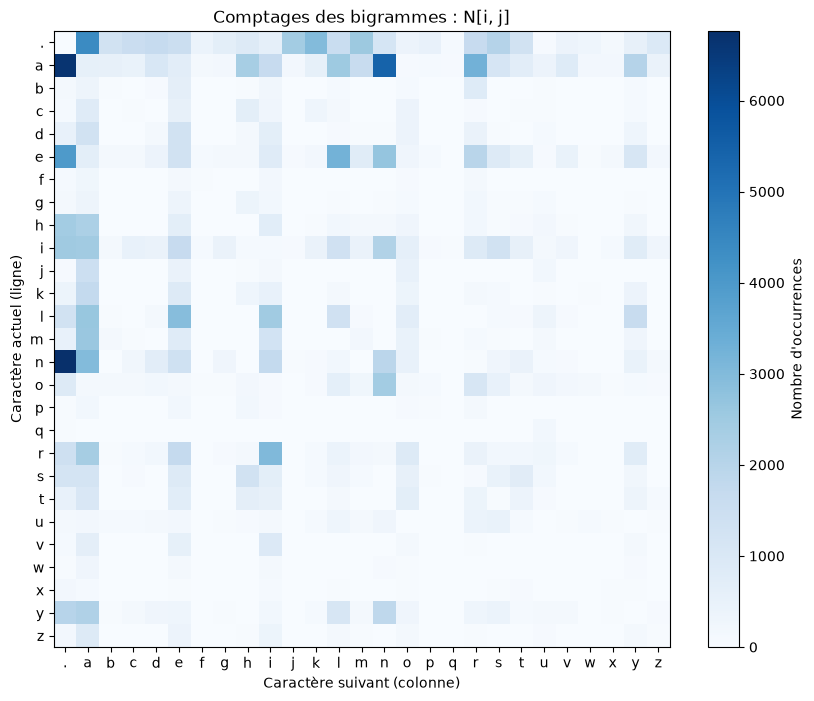

In [25]:
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(N, cmap="Blues")
ax.set_xticks(range(27), [itos[i] for i in range(27)])
ax.set_yticks(range(27), [itos[i] for i in range(27)])
ax.set_xlabel("Caractère suivant (colonne)")
ax.set_ylabel("Caractère actuel (ligne)")
ax.set_title("Comptages des bigrammes : N[i, j]")
fig.colorbar(im, ax=ax, label="Nombre d'occurrences")
plt.show()

**Lire le graphique :** choisir une ligne, puis une colonne. Les cases plus foncées correspondent à des transitions plus fréquentes.

**Question flash :** `N[stoi['a'], stoi['m']]` signifie-t-il « a après m » ou « m après a » ? Vérifier avec un comptage affiché ci-dessus.

## 2. Des comptages aux probabilités

Une distribution de probabilité est constituée de valeurs **positives ou nulles** dont la somme vaut **1**. Pour le caractère courant `i`, on divise chaque case de la ligne par la somme de la ligne :

$$
P(j\mid i)=\frac{N_{ij}}{\sum_k N_{ik}}.
$$

Par exemple, la première ligne donne les probabilités du **premier caractère d'un nom**, car l'indice 0 correspond à `.`.

### Pourquoi diviser par la somme de la ligne ?

Imaginons que la ligne correspondant à `a` contienne, pour trois issues seulement, les comptes `m : 30`, `n : 10`, `. : 10`. Sur **50 occurrences** de `a` comme caractère courant, `m` vient ensuite 30 fois. On estime donc :

$$
P(m\mid a) = \frac{30}{50} = 0{,}60.
$$

La proportion `0,60` s'interprète ainsi : **« parmi les occurrences où le caractère courant est `a`, environ 60 % sont suivies de `m` »**, dans notre exemple imaginaire. Le principe est identique pour `names.txt`.

La division s'effectue **ligne par ligne** parce que nous conditionnons la réponse sur le caractère courant : la distribution après `a` n'est pas celle après `m`.

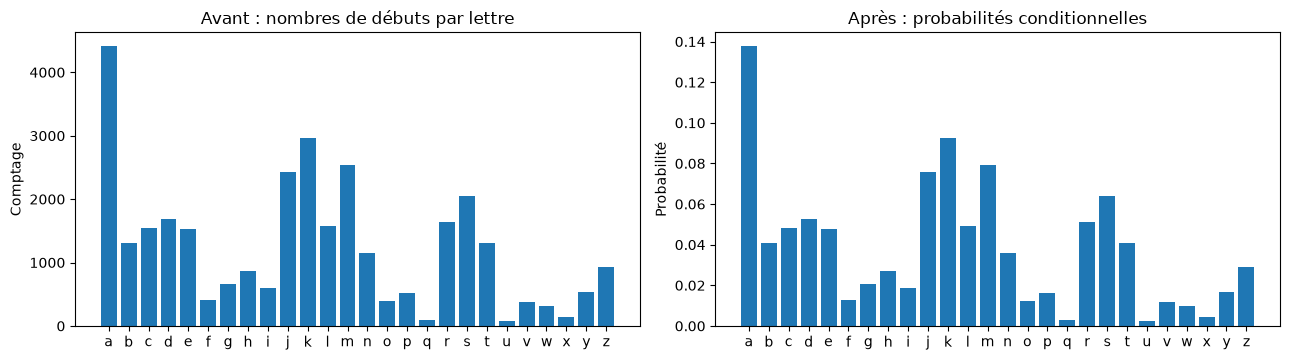

Somme de la ligne après normalisation : 1.0


In [26]:
start_counts = N[0].float()
start_probs = start_counts / start_counts.sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.7))
ax[0].bar(chars, start_counts[1:].numpy())
ax[0].set_title("Avant : nombres de débuts par lettre")
ax[0].set_ylabel("Comptage")
ax[1].bar(chars, start_probs[1:].numpy())
ax[1].set_title("Après : probabilités conditionnelles")
ax[1].set_ylabel("Probabilité")
plt.tight_layout(); plt.show()
print("Somme de la ligne après normalisation :", start_probs.sum().item())

### Normaliser toutes les lignes, puis générer

Chaque **ligne** de `P` est maintenant une distribution `P(next | current)`. Pour la génération :

1. commencer par `.` ;
2. tirer un prochain caractère avec `torch.multinomial` ;
3. recommencer depuis la ligne correspondant au caractère tiré ;
4. s'arrêter quand on tire `.`.


### `torch.multinomial` : transformer une distribution en un choix

Les valeurs de `P[ix]` disent **à quel point chaque prochain caractère est probable**. Elles ne disent pas quel caractère sera effectivement tiré. `torch.multinomial` fait ce tirage aléatoire.

Supposons trois issues, avec `p = [0.6, 0.3, 0.1]` correspondant à `a`, `b`, `c`. Sur un grand nombre de tirages, on observera **environ** 60 % de `a`, 30 % de `b` et 10 % de `c`. Un tirage particulier peut très bien donner `c` : ce n'est pas une erreur !

```python
p = [0.6, 0.3, 0.1]
indice = torch.multinomial(p, num_samples=1, replacement=True).item()
```

- `p` : les poids (ici déjà normalisés). `multinomial` accepte aussi des poids positifs non normalisés.
- `num_samples=1` : nous voulons **un** seul caractère suivant.
- `.item()` : convertir le tenseur scalaire en un entier Python.
- `replacement=True` : autoriser les mêmes indices lors de tirages répétés ; ici, avec un seul tirage par appel, ce paramètre ne change pas le résultat.

**Ne pas confondre avec `argmax`** : `argmax` choisit systématiquement l'issue la plus probable. `multinomial` laisse une chance aux autres issues, ce qui produit des prénoms variés.

**Pourquoi une boucle ?** Après avoir tiré une lettre, elle devient le **nouveau caractère courant** : nous consultons alors une autre ligne de `P`. Quand `.` est tiré, le prénom est terminé.

In [27]:
import torch
p = torch.tensor([0.6, 0.3, 0.1])
torch.multinomial(p, num_samples=1, replacement=True).item()

0

In [64]:
P[0]

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [66]:
P = N.float()
P /= P.sum(dim=1, keepdim=True)
assert torch.allclose(P.sum(dim=1), torch.ones(27))

def sample_names_from_table(P, n=8, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    results = []
    for _ in range(n):
        out = []
        ix = 0
        for _ in range(40): # Limit 40 characters
            ix = torch.multinomial(P[ix], 1, replacement=True, generator=g).item()
            # ix = torch.argmax(P[ix], dim=0).item()
            if ix == 0:
                break
            out.append(itos[ix])
        results.append("".join(out))
    return results

print("Exemples générés :")
for name in sample_names_from_table(P, 8):
    print(f"- {name}")


Exemples générés :
- cexze
- momasurailezitynn
- konimittain
- llayn
- ka
- da
- staiyaubrtthrigotai
- moliellavo


**Discussion :** ces noms peuvent sembler plausibles localement, mais souvent incohérents globalement. Pourquoi ? Car le modèle ne connaît **que le dernier caractère** : il n'a ni mémoire des syllabes, ni notion de prénom entier.


---
## 3. Comment savoir si notre modèle est bon ? De la prédiction à la loss

**Ce que nous savons faire :** compter les transitions, obtenir une table `P`, puis générer des prénoms avec `torch.multinomial`.

**Ce que nous ne savons pas encore faire :** dire **objectivement** si une table de probabilités est meilleure qu'une autre. Deux modèles peuvent générer des prénoms amusants, mais lesquels prédisent réellement mieux les caractères du dataset ?

Nous allons construire un **thermomètre de qualité** : un nombre qui mesure à quel point les prédictions d'un modèle sont compatibles avec les vrais prénoms.

> **Pourquoi est-ce indispensable pour la suite ?** Dans quelques minutes, nous remplacerons la table `P` par une matrice de poids `W` initialisée au hasard. Pour entraîner `W`, il nous faudra un nombre à **minimiser**. C'est ce nombre que nous construisons maintenant : la **loss**.

**Notre chemin en 20 minutes :**

1. Regarder la probabilité donnée à la **bonne réponse**.
2. Étendre cette idée à **toutes les lettres d'un prénom** : *likelihood*.
3. Transformer le produit en somme : *log-likelihood*.
4. Obtenir un coût à minimiser : *negative log-likelihood (NLL)*.
5. Moyennner sur toutes les transitions du dataset : notre **score de modèle**.

### 3.1 — Un test plus fiable que « les prénoms ont l'air jolis »

Imaginons une question de prédiction : **« Je suis au début d'un prénom (`.`). Quelle sera la première lettre ? »**

Le modèle ne répond pas seulement « `e` ». Il propose **27 probabilités**, une pour chaque prochain caractère possible. La vraie réponse, pour le prénom `emma`, est `e`.

Notre première mesure est donc : **quelle probabilité le modèle a-t-il attribuée à cette vraie réponse ?**

Dans notre table déjà calculée :

$$
\underbrace{P(e\mid .)}_{\text{probabilité du vrai prochain caractère}}
=\frac{\underbrace{N[\texttt{.},\texttt{e}]}_{\text{nombre de prénoms commençant par e}}}{\underbrace{\sum_j N[\texttt{.},j]}_{\text{nombre total de prénoms}}}.
$$

Si le résultat vaut **0,0478**, cela signifie : *environ 4,78 % des prénoms de notre dataset commencent par `e`*. **Ce n'est pas la probabilité que `emma` soit un bon prénom**. Cette valeur provient **uniquement du comptage `N`, puis de sa normalisation dans `P`**.

À chaque étape, nous regarderons seulement la probabilité attribuée au **véritable caractère suivant**.


In [29]:
# Le modèle évalué ici est P : la table de probabilités issue des comptages N.

ch1, ch2 = ".", "e"                 # contexte et vraie réponse pour "emma"
i, j = stoi[ch1], stoi[ch2]
nb_bonne_transition = N[i, j].item()  # nombre de bigrammes . → e
nb_transitions_apres_ch1 = N[i].sum().item()  # toutes les transitions après .
p_vraie_reponse = P[i, j].item()      # le rapport entre les deux comptes

print(f"Parmi {nb_transitions_apres_ch1} débuts de prénoms, "
      f"{nb_bonne_transition} commencent par 'e'.")
print(f"P(e | .) = {nb_bonne_transition} / {nb_transitions_apres_ch1} "
      f"= {p_vraie_reponse:.4f} ({100*p_vraie_reponse:.2f} %)")
print(f"Un modèle uniforme donnerait seulement 1/27 = {1/27:.4f} "
      "à chaque caractère.")

Parmi 32033 débuts de prénoms, 1531 commencent par 'e'.
P(e | .) = 1531 / 32033 = 0.0478 (4.78 %)
Un modèle uniforme donnerait seulement 1/27 = 0.0370 à chaque caractère.


### 3.2 — Un prénom contient plusieurs prédictions : la *likelihood*

Pour `emma`, nous avons **cinq questions posées au modèle** :

` . → e ` · ` e → m ` · ` m → m ` · ` m → a ` · ` a → . `

Chaque ligne de `P` donne la probabilité de la **bonne réponse** à sa question. Observons ces cinq valeurs : elles peuvent être très différentes, car les contextes sont différents.

Pour demander **« quelle probabilité ce modèle attribue-t-il à la séquence complète `.emma.` ? »**, nous multiplions les cinq probabilités conditionnelles. C'est la règle de probabilité d'une séquence ; dans un modèle bigramme, chaque prédiction dépend du caractère précédent seulement.

$$
\underbrace{L(\texttt{emma})}_{\substack{\text{likelihood du prénom}\\\text{selon notre modèle}}}
= P(e\mid .)\,P(m\mid e)\,P(m\mid m)\,P(a\mid m)\,P(.\mid a).
$$

**Interprétation :** la *likelihood* est la probabilité que **notre modèle** attribue à cette séquence exacte, en suivant ses distributions successives. Elle ne dit pas si le prénom est « beau » ; elle permet de **comparer deux modèles sur la même observation**.

**Attention :** plus une séquence est longue, plus son produit a tendance à être petit. Ce n'est pas encore un score idéal pour comparer des ensembles de tailles différentes.

In [30]:
# Les cinq transitions d'"emma" : leur probabilité provient de P, donc de N.
sequence = ["."] + list("emma") + ["."]
probabilites = []
labels = []

print("Transition | nombre / total | probabilité de la bonne réponse")
print("-" * 68)
for ch1, ch2 in zip(sequence, sequence[1:]):
    i, j = stoi[ch1], stoi[ch2]
    compte = N[i, j].item()            # combien de fois ch2 suit ch1 ?
    total = N[i].sum().item()          # combien de transitions partent de ch1 ?
    p = P[i, j].item()                 # probabilité conditionnelle
    probabilites.append(p)
    labels.append(f"{ch1} → {ch2}")
    print(f"{ch1} → {ch2:1}      | {compte:5d} / {total:5d} | {p:.4f}")

# Multiplier les probabilités revient à calculer la likelihood du nom.
likelihood_emma = math.prod(probabilites)
print(f"\nLikelihood L('emma') = {likelihood_emma:.8f}")
print(f"Likelihood sous un modèle uniforme = {(1/27)**5:.8f}")

Transition | nombre / total | probabilité de la bonne réponse
--------------------------------------------------------------------
. → e      |  1531 / 32033 | 0.0478
e → m      |   769 / 20423 | 0.0377
m → m      |   168 /  6642 | 0.0253
m → a      |  2590 /  6642 | 0.3899
a → .      |  6640 / 33885 | 0.1960

Likelihood L('emma') = 0.00000348
Likelihood sous un modèle uniforme = 0.00000007


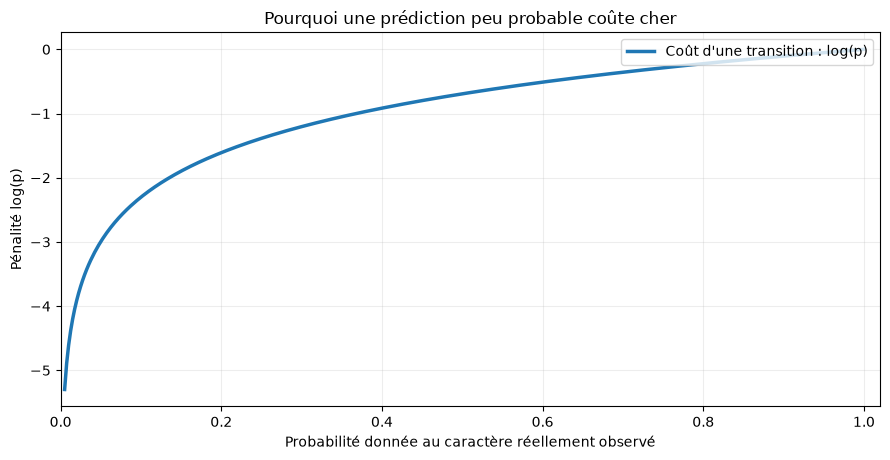

In [70]:
# Visualiser LA fonction de coût que nous venons de définir.
# Les marqueurs correspondent aux vraies transitions du prénom "emma".
p_grid = torch.linspace(0.005, 1, 400)
fig, ax = plt.subplots(figsize=(9, 4.7))
ax.plot(p_grid.numpy(), p_grid.log().numpy(), linewidth=2.5,
        label="Coût d'une transition : log(p)")

ax.set(xlabel="Probabilité donnée au caractère réellement observé",
       ylabel="Pénalité log(p)",
       title="Pourquoi une prédiction peu probable coûte cher")
ax.set_xlim(0, 1.02)
ax.grid(alpha=0.22)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### 3.3 — Pourquoi utiliser le logarithme ?

Notre objectif est de **récompenser les modèles qui attribuent une forte probabilité aux données réelles**. Nous pourrions donc chercher à **maximiser la likelihood**.

Mais multiplier beaucoup de petites probabilités rend rapidement le résultat difficile à lire et, sur de très longues séquences, numériquement minuscule.

Le logarithme donne une écriture plus pratique :

$$
\log(a\times b\times c) = \log(a)+\log(b)+\log(c)
$$

Donc pour un prénom :

$$
\log L(\texttt{emma})
= \log P(e\mid .)+\log P(m\mid e)+\cdots+\log P(.\mid a).
$$

**Pourquoi n'avons-nous rien changé à la préférence entre modèles ?** Parce que `log` est **strictement croissant** : si `L_A > L_B`, alors `log(L_A) > log(L_B)`.

**Pourquoi ces logarithmes sont-ils négatifs ?** Toutes les probabilités valent entre 0 et 1 : `log(1)=0`, mais `log(0,1)≈−2,30`. Plus la probabilité de la bonne réponse est petite, plus son logarithme est négatif.

**La log-likelihood n'est pas une nouvelle façon de prédire** : c'est **une autre échelle pour mesurer** ce que notre modèle pense des vraies données.

Pourquoi utiliser la log likelihood ? Parce que l'architecture Transformer dans le papier de base utilise ce formule aussi.

In [31]:
# Même information, deux écritures : produit des p ou somme des log(p).
log_likelihood_emma = sum(math.log(p) for p in probabilites)

print(f"Likelihood d'emma             : {likelihood_emma:.8f}")
print(f"log de la likelihood         : {math.log(likelihood_emma):+.4f}")
print(f"somme des log-probabilités   : {log_likelihood_emma:+.4f}")

# Sur un corpus entier, il est préférable de sommer les log-probabilités
# plutôt que de multiplier une immense quantité de nombres entre 0 et 1.

Likelihood d'emma             : 0.00000348
log de la likelihood         : -12.5690
somme des log-probabilités   : -12.5690


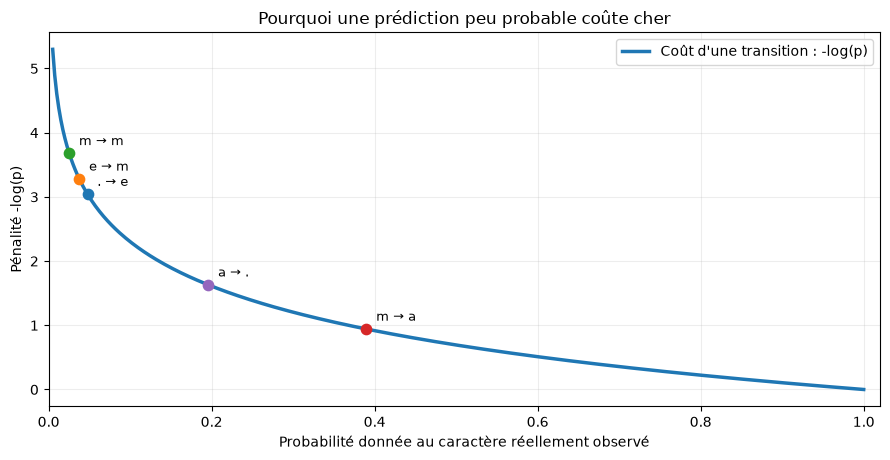

In [32]:
# Visualiser LA fonction de coût que nous venons de définir.
# Les marqueurs correspondent aux vraies transitions du prénom "emma".
p_grid = torch.linspace(0.005, 1, 400)
fig, ax = plt.subplots(figsize=(9, 4.7))
ax.plot(p_grid.numpy(), -p_grid.log().numpy(), linewidth=2.5,
        label="Coût d'une transition : -log(p)")
for label, p in zip(labels, probabilites):
    ax.scatter(p, -math.log(p), s=55, zorder=4)
    ax.annotate(label, (p, -math.log(p)), xytext=(7, 6),
                textcoords="offset points", fontsize=9)
ax.set(xlabel="Probabilité donnée au caractère réellement observé",
       ylabel="Pénalité -log(p)",
       title="Pourquoi une prédiction peu probable coûte cher")
ax.set_xlim(0, 1.02)
ax.grid(alpha=0.22)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### 3.4 — Transformer un score à maximiser en une *loss* à minimiser

Nous souhaitons **maximiser** la log-likelihood : un meilleur modèle doit attribuer une probabilité plus grande aux vraies réponses.

Mais notre future boucle d'entraînement fera de la **descente de gradient**, donc elle cherchera à **minimiser** un coût. Nous changeons simplement de signe :

$$
\boxed{\text{coût d'une transition observée}=-\log(p_\text{vrai})}
$$

Cette quantité s'appelle la **negative log-likelihood (NLL)**.

| Probabilité du caractère réellement observé | Coût `-log(p)` | Ce que cela signifie |
|---:|---:|---|
| `1,00` | `0,00` | Le modèle était certain de la vraie réponse |
| `0,80` | `0,22` | Il l'avait jugée très plausible |
| `0,10` | `2,30` | Il l'avait jugée peu plausible |
| `0,01` | `4,61` | Il était très surpris par la vraie réponse |

**Le graphique ci-dessus ne sort pas de nulle part :** chaque point répond à la question « combien coûte une transition réelle si le modèle lui donnait la probabilité `p` ? ». Nous y marquons aussi les cinq probabilités que **notre modèle de comptage** attribue aux transitions d'`emma`.

**Question :** sur quelles transitions le modèle sera-t-il le plus pénalisé ? Celles auxquelles il a donné les plus faibles probabilités.

### 3.5 — Un score unique sur tout le dataset : la NLL moyenne

Nous savons maintenant attribuer un **coût à une prédiction**. Pour évaluer le modèle sur `names.txt`, nous procédons comme pour une copie contenant de nombreuses questions :

1. pour **chaque transition réelle** du dataset, prendre la probabilité de la vraie réponse dans `P` ;
2. calculer son coût `-log(p)` ;
3. **moyenner** ces coûts, pour obtenir un score par prédiction plutôt qu'un nombre qui grossit mécaniquement avec la taille du dataset.

$$
\boxed{\mathcal{L}(P)
=-\frac{1}{M}\sum_{t=1}^{M}\log P(y_t\mid x_t)}
$$

**Lire la formule :**

- `M` : nombre total de **bigrammes observés** dans le dataset (et non nombre de prénoms) ;
- `x_t` : caractère courant de la transition numéro `t` ;
- `y_t` : **vrai** caractère qui suit ;
- `P(y_t | x_t)` : probabilité donnée à cette bonne réponse par notre **table de comptage** ;
- `log`, puis le signe `−` : pénaliser les transitions jugées improbables ;
- `1/M` : faire la moyenne pour avoir un score comparable.

La **NLL moyenne** est notre *loss*. **Plus elle est faible, meilleur est le modèle sur ces données.**

Pour savoir si le score est bon, comparons à un modèle volontairement naïf : un modèle **uniforme**, qui donne `1/27` à tous les caractères suivants. Sa loss vaut toujours `−log(1/27)=log(27)≈3,30`.

In [33]:
# Évaluer deux modèles sur EXACTEMENT les mêmes transitions du dataset :
# 1) un modèle uniforme (aucune information sur les caractères),
# 2) notre modèle de comptage P (probabilités tirées de names.txt).

nll_table = 0.0
nombre_transitions = 0

for prenom in words:
    sequence = ["."] + list(prenom) + ["."]
    for ch1, ch2 in zip(sequence, sequence[1:]):
        p_vrai = P[stoi[ch1], stoi[ch2]].item()
        # Ce bigramme est dans le dataset, son compte est donc >= 1 : p_vrai > 0.
        nll_table += -math.log(p_vrai)
        nombre_transitions += 1

loss_comptage = nll_table / nombre_transitions
loss_uniforme = math.log(27)

print(f"Nombre de transitions évaluées : {nombre_transitions:,}")
print(f"Loss du modèle uniforme        : {loss_uniforme:.4f}")
print(f"Loss de notre table P          : {loss_comptage:.4f}")
print("Une loss plus petite signifie : les bonnes réponses reçoivent "
      "en moyenne de meilleures probabilités logarithmiques.")

Nombre de transitions évaluées : 228,146
Loss du modèle uniforme        : 3.2958
Loss de notre table P          : 2.4540
Une loss plus petite signifie : les bonnes réponses reçoivent en moyenne de meilleures probabilités logarithmiques.


### Le lien essentiel avec la suite : pourquoi calculer cette loss **avant** de créer un réseau neurones?

Nous avons maintenant **deux choses distinctes** :

- **Un modèle** (`P`) : pour un caractère courant, il prédit 27 probabilités.
- **Un critère d'évaluation** (la NLL moyenne) : à partir de ses probabilités et des **vraies réponses**, il produit un seul nombre.

La table `P` est obtenue directement par comptage ; **nous n'avons rien entraîné par gradient**. Sur le dataset original, elle donne une NLL autour de **2,45**, contre **3,30** pour l'uniforme. Ce score est mesuré **sur les données qui ont servi aux comptages** : ce n'est pas une preuve de généralisation.

**La question qui lance la section suivante :** et si nous ne calculions plus les probabilités avec des comptages ? Si elles provenaient d'une matrice de poids `W` initialisée au hasard, **comment modifier `W` pour diminuer cette même loss ?**

La réponse sera : **forward pass → probabilités → même NLL → gradients → mise à jour de `W`**.

> À retenir : la loss n'est pas une particularité du modèle bigramme. C'est le **signal d'apprentissage** que nous réutiliserons lorsque les logits seront produits par un réseau de neurones, puis par un Transformer.

---
## 4. Du modèle de comptage à un réseau de neurones

### 4.1 — Pourquoi construire un réseau alors que nous avons déjà `P` ?

**Rappel de la section 3.** Nous savons désormais donner une note à un modèle : sa **negative log-likelihood (NLL) moyenne** sur de vrais bigrammes. Plus ce nombre est faible, plus le modèle attribue, en moyenne, de fortes probabilités aux caractères réellement observés.

Notre premier modèle fonctionne déjà : il construit `P` en comptant les transitions dans `names.txt`. **Pour un simple bigramme, compter est même la méthode la plus directe !** Nous ne prétendons pas que le réseau sera meilleur que les comptages.

**Notre nouveau défi :** peut-on obtenir le *même genre de table de probabilités*, **sans compter directement**, en partant d'une matrice de nombres que l'on pourra modifier grâce aux gradients ?

| Modèle construit jusqu'ici | Modèle que nous allons entraîner |
|:---|:---|
| On compte les transitions dans `N`. | On initialise au hasard des nombres dans `W`. |
| On divise chaque ligne de `N` par sa somme pour obtenir `P`. | On transformera chaque ligne de `W` en probabilités avec **softmax** (section 5). |
| Une ligne = « que peut-il suivre pour ce caractère ? » | Une ligne = « quels scores donner aux prochains caractères ? » |
| Les probabilités viennent directement du dataset. | Les probabilités viendront des poids ajustés par la loss. |

**Notre fil conducteur :** `caractère courant → ligne de W → probabilités → loss → mise à jour de W`.

> **À retenir :** `N` = nombres de transitions observées ; `P` = probabilités obtenues par comptage ; `W` = **paramètres entraînables**, qui ne sont ni des comptages ni encore des probabilités. Les trois ont la forme `(27, 27)`, mais pas la même signification.

### 4.2 — Avant de penser « réseau », que sont les *entrées* et les *bonnes réponses* ?

Une machine ne s'entraîne pas directement avec la chaîne de caractères `"emma"` : pour **chaque transition**, elle reçoit une entrée et une réponse attendue.

Nous savons déjà fabriquer des indices grâce à `stoi` : `'.' → 0`, `'a' → 1`, …, `'m' → 13`.

Voici les **cinq exercises** cachés dans un seul prénom :

| Exercise | Caractère donné (`x`) | Réponse attendue (`y`) | Indices `(xs, ys)` |
|---:|:---:|:---:|:---:|
| 1 | `.` | `e` | `(0, 5)` |
| 2 | `e` | `m` | `(5, 13)` |
| 3 | `m` | `m` | `(13, 13)` |
| 4 | `m` | `a` | `(13, 1)` |
| 5 | `a` | `.` | `(1, 0)` |

- `xs` contient **les cinq entrées** : l'indice du caractère courant.
- `ys` contient **les cinq bonnes réponses** : l'indice du caractère suivant.

**Pourquoi garder `ys` ?** Comme dans la section 3, c'est la vraie réponse qui permet de mesurer si la prédiction est bonne : `xs` est ce que le réseau **voit**, `ys` est ce qu'on lui **demande de prédire**.

**Question à la classe :** pourquoi `m` apparaît-il deux fois dans `xs` ? Parce que deux bigrammes de `emma` commencent par `m` : `m→m` et `m→a`. Le même contexte peut avoir plusieurs réponses possibles !

In [34]:
# Construisons des exemples d'apprentissage, comme nous l'avons fait pour compter les bigrammes.
sequence = ["."] + list("emma") + ["."]
transitions = list(zip(sequence, sequence[1:]))  # (caractère courant, caractère attendu)

xs_small = torch.tensor([stoi[ch1] for ch1, ch2 in transitions], dtype=torch.long)
ys_small = torch.tensor([stoi[ch2] for ch1, ch2 in transitions], dtype=torch.long)

for t, ((ch1, ch2), x, y) in enumerate(zip(transitions, xs_small, ys_small), start=1):
    print(f"Exemple {t} : entrée '{ch1}' (x={x.item():2d}) "
          f"→ vraie réponse '{ch2}' (y={y.item():2d})")

print("\nxs_small =", xs_small.tolist(), " | shape =", tuple(xs_small.shape))
print("ys_small =", ys_small.tolist(), " | shape =", tuple(ys_small.shape))
# Cinq transitions = cinq entrées, cinq réponses : deux tenseurs de shape (5,).

Exemple 1 : entrée '.' (x= 0) → vraie réponse 'e' (y= 5)
Exemple 2 : entrée 'e' (x= 5) → vraie réponse 'm' (y=13)
Exemple 3 : entrée 'm' (x=13) → vraie réponse 'm' (y=13)
Exemple 4 : entrée 'm' (x=13) → vraie réponse 'a' (y= 1)
Exemple 5 : entrée 'a' (x= 1) → vraie réponse '.' (y= 0)

xs_small = [0, 5, 13, 13, 1]  | shape = (5,)
ys_small = [5, 13, 13, 1, 0]  | shape = (5,)


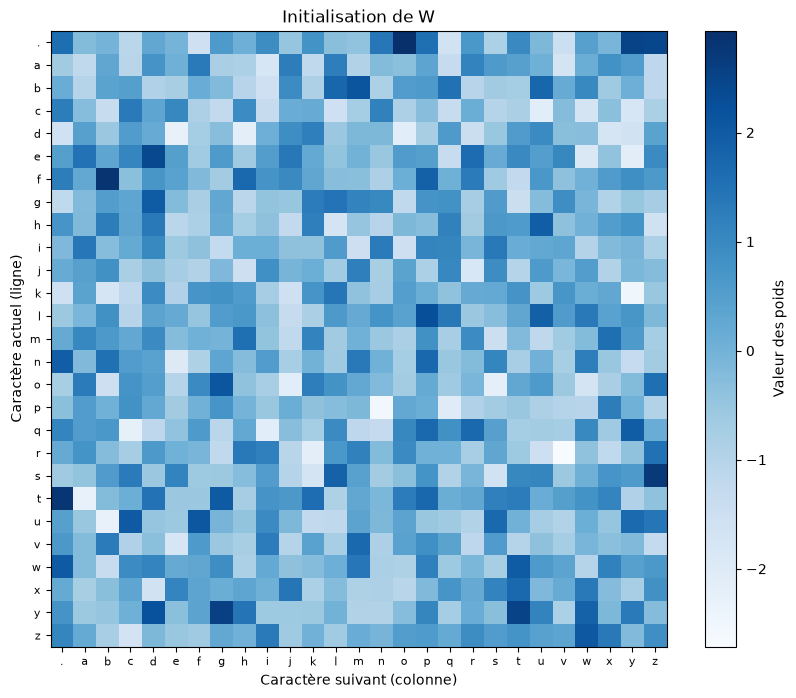

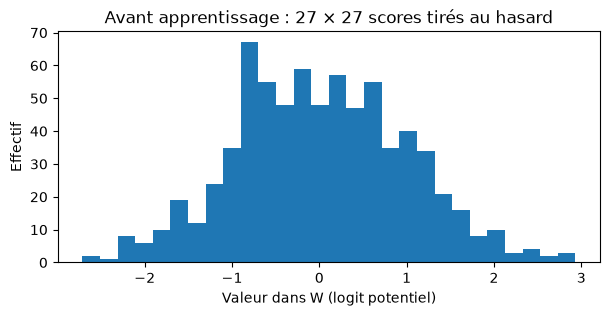

W_example.shape = (27, 27)
Un score négatif est autorisé dans W : True


In [77]:
g = torch.Generator().manual_seed(SEED)
W_example = torch.randn((27, 27), generator=g)
plot_matrice_caracteres(
    W_example,
    itos,
    title="Initialisation de W",
    cbar_label="Valeur des poids",
)
plt.show()

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(W_example.flatten().numpy(), bins=28)
ax.set_title('Avant apprentissage : 27 × 27 scores tirés au hasard')
ax.set_xlabel('Valeur dans W (logit potentiel)')
ax.set_ylabel('Effectif')
plt.show()

print('W_example.shape =', tuple(W_example.shape))
print('Un score négatif est autorisé dans W :', bool((W_example < 0).any()))

### 4.3 — Pourquoi ne pas donner directement l'indice `13` au réseau ?

Imaginez que l'on fournisse le nombre `13` pour représenter `m`. **Ce nombre est une étiquette arbitraire** : il ne signifie pas que `m` est 13 fois plus grand que `a`, ni qu'il est « proche » de `l` parce que leurs indices sont voisins.

Or nous voulons appliquer une opération matricielle à une représentation du caractère. Une idée simple consiste à donner **une case à chaque symbole** :

- un vecteur de **27 cases**, une pour chaque caractère autorisé (`.`, `a`, …, `z`) ;
- **26 zéros** et **un unique `1`** à la case du caractère observé ;
- pour `m` (indice 13), la case numéro 13 vaut `1` et toutes les autres valent `0`.

Cet encodage s'appelle **one-hot** (« une seule case active »). Il ne prétend pas apprendre la signification des lettres. Il indique uniquement **quelle lettre est présente**.

> **Pourquoi `xenc_small` aura-t-il la shape `(5, 27)` ?** Nous avons **5 exemples** (`emma` possède 5 transitions) et, pour **chaque exemple**, un vecteur de **27 valeurs**. Donc 5 lignes × 27 colonnes.
>
> `xs_small.shape == (5,)` → `one_hot(xs_small).shape == (5,27)`.

Les réseaux modernes utilisent souvent des **embeddings appris**, plus compacts ou plus expressifs selon le problème. Le one-hot est ici un choix volontairement **naïf et transparent** : il permet de comprendre exactement comment une lettre sélectionne la ligne d'une matrice.

Shape des indices xs    : (5,)
Shape des entrées one-hot: (5, 27)
Indices des cases actives: [0, 5, 13, 13, 1]
Nombre de 1 par ligne   : [1.0, 1.0, 1.0, 1.0, 1.0]


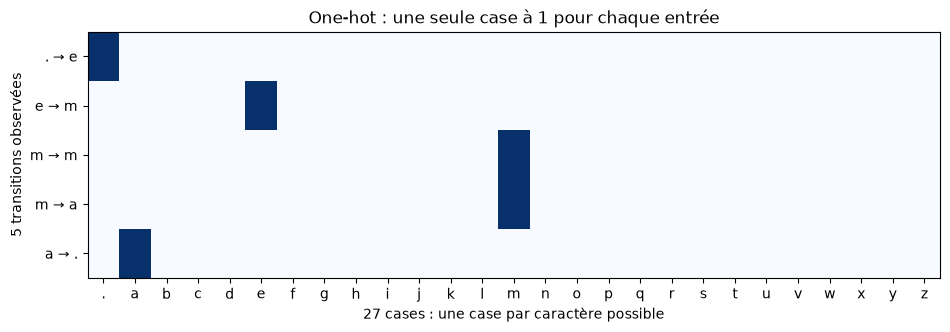

In [35]:
# Transformer les cinq entiers en cinq vecteurs de 27 composantes.
# F.one_hot retourne des entiers (0/1). .float() permet le produit matriciel avec W (float).
xenc_small = F.one_hot(xs_small, num_classes=27).float()

print("Shape des indices xs    :", tuple(xs_small.shape))
print("Shape des entrées one-hot:", tuple(xenc_small.shape))
print("Indices des cases actives:", xenc_small.argmax(dim=1).tolist())
print("Nombre de 1 par ligne   :", xenc_small.sum(dim=1).tolist())

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.imshow(xenc_small.numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(27), [itos[i] for i in range(27)])
ax.set_yticks(range(5), [f"{a} → {b}" for a, b in transitions])
ax.set_xlabel("27 cases : une case par caractère possible")
ax.set_ylabel("5 transitions observées")
ax.set_title("One-hot : une seule case à 1 pour chaque entrée")
plt.show()

### 4.4 — Que se passe-t-il vraiment quand on multiplie un one-hot par `W` ?

**Ne partons pas directement de 27 × 27.** Construisons une petite table fictive avec seulement **3 caractères** (`a`, `b`, `c`). Chaque ligne représente le caractère *courant* et chaque colonne le *caractère suivant*.


a) Supposons cette matrice de **scores** (pas encore des probabilités) :

$$
W_{\mathrm{mini}}=
\begin{bmatrix}
2 & 1 & 0\\
4 & 5 & 6\\
7 & 8 & 9
\end{bmatrix}
$$

b) Si le caractère courant est `b`, son encodage one-hot est :

$$
x_b=\begin{bmatrix}0 & 1 & 0\end{bmatrix}.
$$

c) Faisons la multiplication **colonne par colonne** :

$$
\begin{aligned}
x_b W_{\mathrm{mini}}
&= \left[\; 0\times 2 + 1\times 4 + 0\times 7,\right. \\
&\qquad \left. 0\times 1 + 1\times 5 + 0\times 8,\right. \\
&\qquad \left. 0\times 0 + 1\times 6 + 0\times 9 \;\right] \\
&= \begin{bmatrix} 4 & 5 & 6 \end{bmatrix}.
\end{aligned}
$$

**Pourquoi exactement cette ligne ?** Les `0` annulent les contributions des lignes `a` et `c` ; le `1` conserve **toute la ligne `b`**. Ce produit est un mécanisme de **sélection d'une ligne**, pas un mélange des caractères.

**Et si le one-hot était `[1,0,0]` ?** Nous obtiendrions `[2,1,0]` : la ligne `a`.

**Question avant d'exécuter le code :** le résultat de la multiplication est-il déjà une distribution de probabilités ? **Non** : `[4,5,6]` ne somme pas à 1. Ce sont seulement des *scores*. La transformation en probabilités sera précisément le sujet de la section 5.

In [36]:
# Démonstration indépendante du dataset : seulement trois caractères a, b, c.
W_mini = torch.tensor([
    [2., 1., 0.],  # Scores si le caractère courant est 'a'
    [4., 5., 6.],  # Scores si le caractère courant est 'b'
    [7., 8., 9.],  # Scores si le caractère courant est 'c'
])
x_b = torch.tensor([0., 1., 0.])  # 'b' = deuxième case active

resultat = x_b @ W_mini
print("x_b =", x_b.tolist())
print("W_mini =\n", W_mini)
print("x_b @ W_mini =", resultat.tolist())
print("ligne de b =", W_mini[1].tolist())
assert torch.equal(resultat, W_mini[1])
# La sélection d'une ligne par one-hot est une IDENTITÉ algébrique.

x_b = [0.0, 1.0, 0.0]
W_mini =
 tensor([[2., 1., 0.],
        [4., 5., 6.],
        [7., 8., 9.]])
x_b @ W_mini = [4.0, 5.0, 6.0]
ligne de b = [4.0, 5.0, 6.0]


### 4.5 — Refaire exactement la même chose sur les cinq bigrammes d'`emma`

Nous revenons à nos **27 caractères**. Créons une matrice `W_exemple` de shape `(27,27)` avec des scores aléatoires, uniquement pour observer le mécanisme :

$$
\underbrace{X_{\mathrm{one\text{-}hot}}}_{(5,27)}
\;@\;
\underbrace{W}_{(27,27)}
\;=\;
\underbrace{\mathrm{scores}}_{(5,27)}.
$$

**Lire les trois dimensions :**

- **5** : nous prédisons le prochain caractère pour **cinq transitions**.
- **27 au milieu** : les 27 cases du one-hot correspondent aux **27 lignes** disponibles dans `W` ; ces dimensions doivent coïncider.
- **27 à la sortie** : pour chaque entrée, nous récupérons **27 scores**, un pour chaque prochain caractère possible.

Dans `emma`, les transitions n°3 et n°4 ont la **même entrée** (`m`). Elles doivent donc sélectionner **la même ligne de `W`**, même si leurs bonnes réponses sont différentes (`m` puis `a`). C'est une limite intrinsèque du bigramme : il ne connaît pas l'histoire précédente.

xenc_small.shape : (5, 27)
W_exemple.shape  : (27, 27)
scores_5.shape   : (5, 27)
Premier caractère courant : .
one-hot @ W == W[indice] ? True
Même entrée 'm' aux exercices 3 et 4 ? True
Mêmes 27 scores pour ces deux exercices ? True


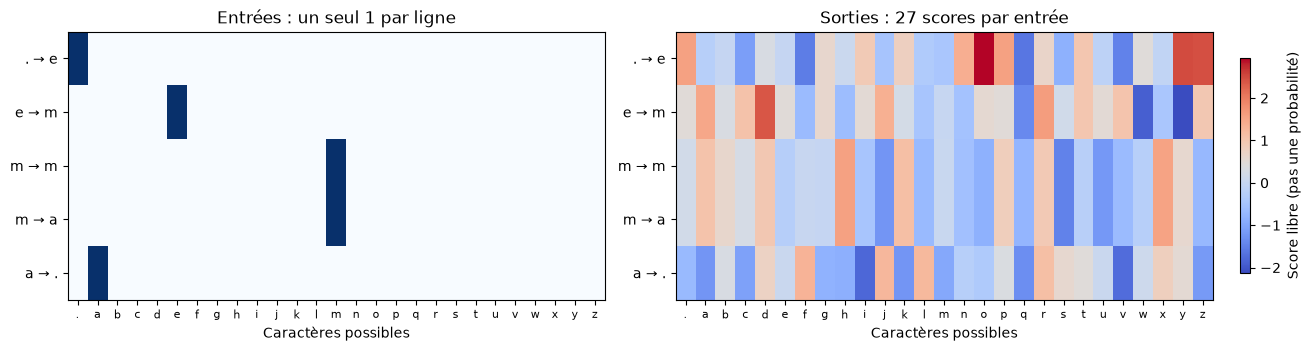

In [37]:
# W_exemple sert SEULEMENT à montrer la sélection : aucune optimisation ici.
# Ses 27 × 27 scores sont aléatoires, et ne sont PAS les probabilités P.
g_section4 = torch.Generator().manual_seed(SEED)
W_exemple = torch.randn((27, 27), generator=g_section4)

scores_5 = xenc_small @ W_exemple
print("xenc_small.shape :", tuple(xenc_small.shape))
print("W_exemple.shape  :", tuple(W_exemple.shape))
print("scores_5.shape   :", tuple(scores_5.shape))

# Comparons le calcul matriciel à une lecture directe de lignes.
print("Premier caractère courant :", itos[xs_small[0].item()])
print("one-hot @ W == W[indice] ?", torch.allclose(scores_5, W_exemple[xs_small]))
print("Même entrée 'm' aux exercices 3 et 4 ?", xs_small[2].item() == xs_small[3].item())
print("Mêmes 27 scores pour ces deux exercices ?", torch.allclose(scores_5[2], scores_5[3]))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), constrained_layout=True)
axes[0].imshow(xenc_small.numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
axes[0].set_title("Entrées : un seul 1 par ligne")
im = axes[1].imshow(scores_5.numpy(), cmap="coolwarm", aspect="auto")
axes[1].set_title("Sorties : 27 scores par entrée")
for ax in axes:
    ax.set_xticks(range(27), [itos[i] for i in range(27)], fontsize=8)
    ax.set_yticks(range(5), [f"{a} → {b}" for a, b in transitions])
    ax.set_xlabel("Caractères possibles")
fig.colorbar(im, ax=axes[1], label="Score libre (pas une probabilité)", shrink=0.8)
plt.show()

In [ ]:
plot_matrice_caracteres(
    W_exemple,
    itos,
    title="Initialisation de W : normale N(0, 1)",
    cbar_label="Valeur des poids",
)
plt.show()

### 4.6 — Le problème qui conduit naturellement au *forward pass*

Nous avons réussi une première chose : **partir d'un caractère et récupérer 27 scores modifiables**.

Mais attention :

- ces scores peuvent être **négatifs** ;
- ils ne somment **pas à 1** ;
- ils ne correspondent donc **pas encore à des probabilités** ;
- nous **ne pouvons pas encore utiliser la même NLL** que dans la section 3, qui a besoin de probabilités pour la vraie réponse.

**La question qui ouvre la section 5 :** comment transformer **n'importe quelle ligne de scores** produite par `W` en une distribution de 27 probabilités (positives, de somme 1) ?

La réponse sera : **exponentielle → normalisation**, autrement dit le **softmax**. Nous pourrons alors retrouver exactement la chaîne d'apprentissage recherchée :

$$
\boxed{\text{indices}\to\text{one-hot}\to\text{scores de }W\to
\text{probabilités}\to\text{NLL}\to\text{gradients}}
$$

**Mini-vérification orale (30 secondes).** Si le caractère courant est `m`, quelle ligne de `W` est sélectionnée ? Pourquoi deux occurrences de `m` produisent-elles exactement les mêmes scores ? Qu'est-ce qui manque encore pour calculer la loss ?

> **Bilan de la section :** nous n'avons pas encore appris à prédire. Nous avons construit la **représentation des entrées** et le **mécanisme qui produit des scores à partir de poids entraînables**. La section 5 expliquera comment ces scores deviennent des probabilités, et la section 6 comment la loss sert à modifier les poids.

---
## 5. Du score à la probabilité : construire le *forward pass*

### 5.1 — Le problème que nous avons laissé en suspens

**Où en sommes-nous ?**

- **Section 3 :** nous avons construit une **loss** qui permet de noter un modèle à partir des probabilités qu'il attribue aux bonnes réponses : $-\log(p)$.
- **Section 4 :** nous avons construit des **entrées one-hot** et une **matrice de poids `W`**. Le calcul `xenc_small @ W` nous donne **27 scores pour chaque caractère courant**.
- **Ce qui nous manque :** ces scores ne sont **pas** des probabilités ; nous ne pouvons donc pas encore leur appliquer la loss de la section 3.

**Notre objectif pendant ces 15 minutes :** transformer les scores d'une ligne de `W` en une distribution de probabilités. Il nous faut alors deux propriétés :

1. chaque probabilité doit être **comprise entre 0 et 1** ;
2. les 27 probabilités d'une ligne doivent **s'additionner à 1**.

**Question à poser avant le code :** pourquoi ne pas stocker directement 27 probabilités dans `W` ? Parce qu'un changement arbitraire d'un poids pourrait créer un nombre négatif ou rompre la somme égale à 1. En laissant `W` contenir **des scores sans contraintes**, puis en les transformant, notre futur entraînement pourra ajuster librement les poids.

> Fil conducteur : **caractère courant → one-hot → ligne de `W` → scores (*logits*) → probabilités → loss**.

### 5.2 — Première difficulté : nos scores ne sont pas positifs

Reprenons trois caractères fictifs possibles après une lettre : `a`, `b`, `c`. Supposons que `W` nous fournisse les **logits** suivants :

| Prochain caractère | `a` | `b` | `c` |
|---|---:|---:|---:|
| Score (logit) | −1 | 0 | 1 |

**Comment lire ces scores ?** Le score 1 exprime une préférence plus forte pour `c` que le score 0 pour `b` ou −1 pour `a`. Mais **1 n'est pas une probabilité de 100 %**, et −1 ne peut pas être une probabilité négative.

Nous avons besoin d'une transformation qui :

- transforme **tous les nombres réels en nombres strictement positifs** ;
- **conserve leur ordre** : un score plus haut doit conserver un poids plus grand ;
- soit **dérivable**, car nous voulons entraîner `W` par gradient.

L'**exponentielle** remplit ces conditions : $e^{-1}\approx 0{,}368$, $e^0=1$, $e^1\approx 2{,}718$.

On appelle ces nombres des **poids positifs non normalisés**. Dans le code d'origine, la variable est nommée `counts` par analogie avec des comptages : **ce ne sont pas les comptes observés dans `N`**.

In [38]:
# Exemple jouet, indépendant de names.txt : trois issues seulement.
# Ce sont des SCORES, pas encore des probabilités.
logits_jouet = torch.tensor([-1.0, 0.0, 1.0])
poids_jouet = logits_jouet.exp()  # exp() est appliquée à chaque élément

for caractere, score, poids in zip('abc', logits_jouet, poids_jouet):
    print(f"{caractere} : logit={score.item():+.1f} → exp(logit)={poids.item():.3f}")

print("Somme des poids :", round(poids_jouet.sum().item(), 3))
print("Cette somme n'est pas 1 : nous ne sommes PAS encore à l'étape des probabilités.")

a : logit=-1.0 → exp(logit)=0.368
b : logit=+0.0 → exp(logit)=1.000
c : logit=+1.0 → exp(logit)=2.718
Somme des poids : 4.086
Cette somme n'est pas 1 : nous ne sommes PAS encore à l'étape des probabilités.


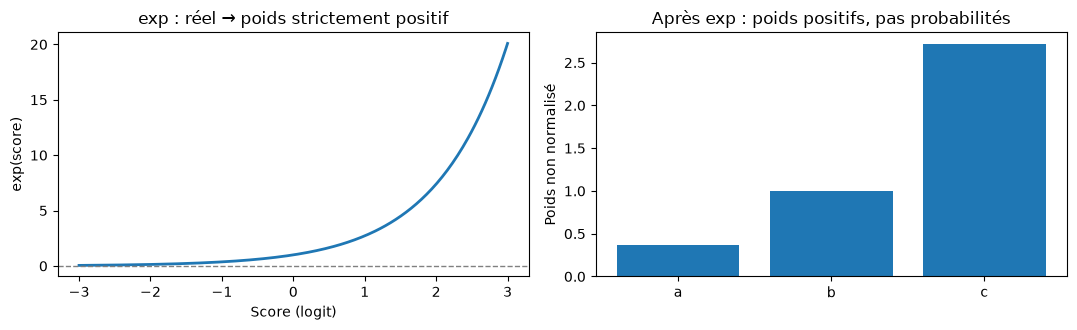

In [39]:
# On visualise pourquoi exp() est utile, sans la confondre avec une probabilité.
z = torch.linspace(-3, 3, 250)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(z.numpy(), z.exp().numpy(), linewidth=2)
axes[0].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[0].set_title('exp : réel → poids strictement positif')
axes[0].set_xlabel('Score (logit)')
axes[0].set_ylabel('exp(score)')
axes[1].bar(list('abc'), poids_jouet.numpy())
axes[1].set_title('Après exp : poids positifs, pas probabilités')
axes[1].set_ylabel('Poids non normalisé')
plt.tight_layout()
plt.show()

### 5.3 — Deuxième difficulté : les poids positifs ne somment pas à 1

Nous avons maintenant des poids positifs : environ $[0{,}368; 1; 2{,}718]$. Leur somme vaut environ $4{,}086$ : **ce n'est toujours pas une distribution de probabilités**.

Rappel de la section 2 : **pour transformer des poids positifs en proportions, on divise chacun par la somme de tous**.

$$
p_j = \frac{\exp(s_j)}{\exp(s_a)+\exp(s_b)+\exp(s_c)}.
$$

Dans cet exemple, on obtient environ $[0{,}090; 0{,}245; 0{,}665]$. Nous pouvons désormais dire : **le modèle attribue 66,5 % de probabilité à `c`** (pour cette situation fictive).

**Pourquoi ces proportions sont-elles correctes ?** Le numérateur est positif, le dénominateur est la somme de tous les numérateurs : chaque résultat est entre 0 et 1, et la somme des résultats est 1.

La combinaison **exponentielle + division par la somme** porte un nom : **softmax**.

> **Ne pas confondre :** `exp` ne « choisit » pas un caractère. Le softmax calcule une *distribution* ; c'est `torch.multinomial` (vu en section 2) qui pourra ensuite tirer un caractère à partir de celle-ci.

In [40]:
# La seconde étape : transformer les poids en PROBABILITÉS.
probs_jouet = poids_jouet / poids_jouet.sum()

for caractere, score, poids, proba in zip('abc', logits_jouet, poids_jouet, probs_jouet):
    print(f"{caractere} : logit={score.item():+.1f}  |  exp={poids.item():.3f}  |  p={proba.item():.3f}")

print("Somme des probabilités :", probs_jouet.sum().item())
assert torch.allclose(probs_jouet.sum(), torch.tensor(1.0))
assert torch.allclose(probs_jouet, torch.softmax(logits_jouet, dim=0))
print("Même résultat avec torch.softmax : oui !")

a : logit=-1.0  |  exp=0.368  |  p=0.090
b : logit=+0.0  |  exp=1.000  |  p=0.245
c : logit=+1.0  |  exp=2.718  |  p=0.665
Somme des probabilités : 1.0
Même résultat avec torch.softmax : oui !


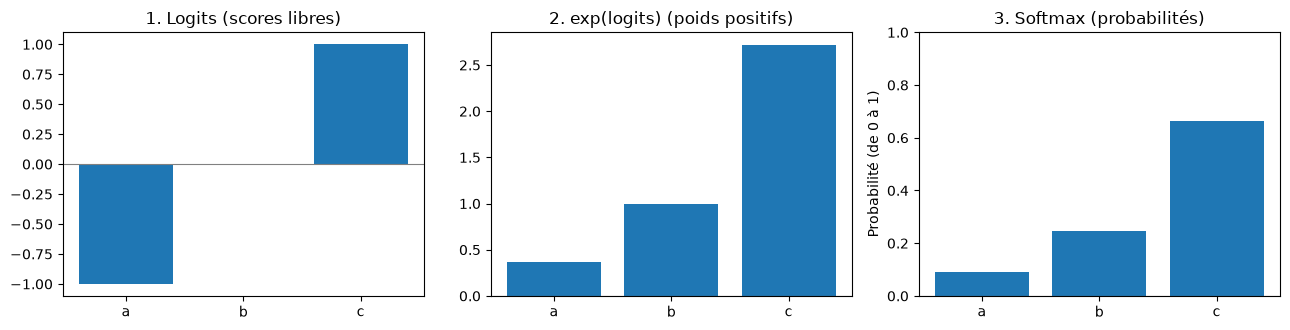

In [41]:
# Même exemple, trois états : scores → poids positifs → probabilités.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, valeurs, titre in zip(
    axes,
    [logits_jouet, poids_jouet, probs_jouet],
    ['1. Logits (scores libres)', '2. exp(logits) (poids positifs)', '3. Softmax (probabilités)']
):
    ax.bar(list('abc'), valeurs.numpy())
    ax.set_title(titre)
    ax.axhline(0, linewidth=0.8, color='gray')
axes[2].set_ylim(0, 1)
axes[2].set_ylabel('Probabilité (de 0 à 1)')
plt.tight_layout()
plt.show()

### 5.4 — Revenons à `emma` : calculer le véritable *forward pass*

Notre exemple à trois scores nous a appris la recette. Appliquons-la maintenant à la matrice de notre réseau, où il y a **27 caractères possibles**, et où nous voulons prédire le prochain caractère pour les **5 transitions d'`emma`**.

**D'abord, initialiser `W`.** Nous choisissons `W = torch.randn((27, 27))`. Chaque nombre est tiré aléatoirement d'une loi normale centrée réduite. L'initialisation n'utilise ni `N` ni `P` : les prédictions sont donc, à ce stade, **non entraînées**.

Ensuite, pour chaque ligne :

1. `xenc_small` : les **5 entrées** one-hot, chacune contenant 27 cases → shape **`(5, 27)`** ;
2. `logits_small = xenc_small @ W_demo` : les **5 lignes de scores** sélectionnées dans `W` → **`(5, 27)`** ;
3. `counts_small = logits_small.exp()` : les mêmes valeurs, transformées en **poids strictement positifs** → **`(5, 27)`** ;
4. `probs_small = counts_small / counts_small.sum(dim=1, keepdim=True)` : **chaque ligne est divisée par sa propre somme** → **`(5, 27)`**.

La dimension `dim=1` correspond aux **27 caractères de sortie**. Nous normalisons **chaque observation indépendamment** ; nous ne voulons surtout pas mélanger les 5 exemples. Avec `keepdim=True`, les sommes ont une shape `(5, 1)`, ce qui permet de diviser les 27 valeurs de chaque ligne par **leur propre** somme.

$$
\underbrace{(5,27)}_{\text{entrées one-hot}}
\;@\;\underbrace{(27,27)}_{W}
\;\longrightarrow\;
\underbrace{(5,27)}_{\text{logits}}
\;\xrightarrow{\exp\text{ puis normaliser}}\;
\underbrace{(5,27)}_{\text{probabilités}}.
$$

**Point important :** le mot *forward pass* désigne le trajet des **entrées vers les prédictions**, à paramètres fixes. À cette étape, `W` ne change pas. Le **backward pass** de la section 6 servira à apprendre.

In [74]:
# LES QUATRE LIGNES À RETENIR : le forward pass du bigramme neuronal.
# Les variables xs_small et xenc_small viennent de la section 4.
# xenc_small a 5 lignes : une par transition du prénom emma.

g = torch.Generator().manual_seed(SEED)
W_demo = torch.randn((27, 27), generator=g)

xenc = F.one_hot(xs_small, num_classes=27).float()  # (5, 27) : les entrées
logits_small = xenc @ W_demo                        # (5, 27) : scores libres
counts_small = logits_small.exp()                   # (5, 27) : poids positifs, PAS N
probs_small = counts_small / counts_small.sum(dim=1, keepdim=True)  # (5, 27)

# On réutilisera xenc_small dans la section 6 : ici, les deux sont identiques.
assert torch.equal(xenc, xenc_small)
assert torch.allclose(logits_small[0], W_demo[xs_small[0]])
assert torch.allclose(probs_small.sum(dim=1), torch.ones(5))

print('Entrées         :', tuple(xenc.shape))
print('Scores / logits :', tuple(logits_small.shape))
print('Sommes de lignes avant division :', counts_small.sum(dim=1).round(decimals=3).tolist())
print('Sommes de lignes après division :', probs_small.sum(dim=1).tolist())
print('Même résultat avec F.softmax ? :', torch.allclose(probs_small, F.softmax(logits_small, dim=1)))

Entrées         : (5, 27)
Scores / logits : (5, 27)
Sommes de lignes avant division : [79.01399993896484, 55.32699966430664, 38.9119987487793, 38.9119987487793, 34.16299819946289]
Sommes de lignes après division : [1.0000001192092896, 0.9999998807907104, 0.9999999403953552, 0.9999999403953552, 1.0]
Même résultat avec F.softmax ? : True


### 5.5 — Lire enfin une probabilité *produite par le réseau*

Nous avons maintenant deux façons de répondre à la **même question** : « après `m`, quelle est la probabilité du caractère `a` ? »

- **Table de comptage `P` (section 2) :** `P[stoi['m'], stoi['a']]` est une **fréquence observée** dans le dataset ;
- **Réseau non entraîné (section 5) :** `probs_small[3, stoi['a']]` est une **probabilité produite par le softmax de la ligne `W['m']`**. L'exemple n°4 d'`emma` est précisément `m → a` (index 3 en Python).

Ces deux probabilités répondent à la même question, **mais elles n'ont aucune raison d'être proches pour l'instant** : `P` a été obtenue en comptant, `W_demo` contient du hasard.

Nous allons afficher la distribution complète après `m`, puis lire l'entrée `m → a`. C'est la même méthode de lecture que pour la table `P` — seule l'origine des probabilités change.

m → a selon les comptages P : 0.3899
m → a selon W aléatoire   : 0.0737
Deux occurrences de m = mêmes probabilités : True


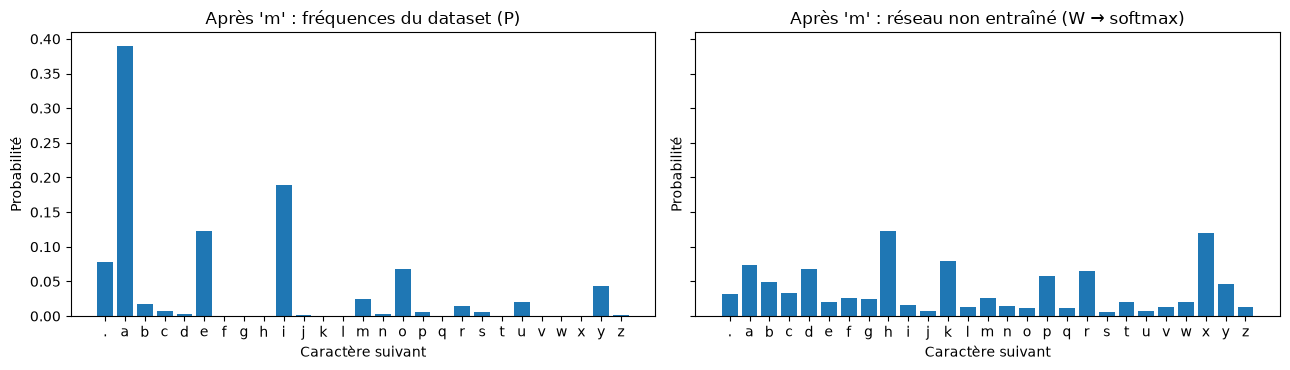

In [44]:
# Même contexte 'm', deux origines possibles de la distribution.
i_m, i_a = stoi['m'], stoi['a']
ligne_apprise_non_entrainee = probs_small[3]  # 4e transition d'emma : m → a
ligne_comptage = P[i_m]                       # P vient de N, section 2

print(f"m → a selon les comptages P : {ligne_comptage[i_a].item():.4f}")
print(f"m → a selon W aléatoire   : {ligne_apprise_non_entrainee[i_a].item():.4f}")
print('Deux occurrences de m = mêmes probabilités :',
      torch.allclose(probs_small[2], probs_small[3]))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, distribution, titre in zip(
    axes, [ligne_comptage, ligne_apprise_non_entrainee],
    ["Après 'm' : fréquences du dataset (P)", "Après 'm' : réseau non entraîné (W → softmax)"]
):
    ax.bar(range(27), distribution.numpy())
    ax.set_xticks(range(27), [itos[i] for i in range(27)])
    ax.set_title(titre)
    ax.set_xlabel('Caractère suivant')
    ax.set_ylabel('Probabilité')
plt.tight_layout()
plt.show()

### 5.6 — Pourquoi avons-nous appris tout cela ? La loss devient calculable

**Nous avons maintenant refermé la boucle commencée en section 3** :

- Nous connaissons les **bonnes réponses** `ys_small` pour les 5 transitions d'`emma`.
- Nous possédons 5 lignes de **probabilités prédites** dans `probs_small`.
- Nous pouvons prendre, dans chaque ligne, **la probabilité attribuée à la bonne réponse**, puis calculer la **même NLL moyenne** qu'avant.

Pour chaque exemple $t$, la probabilité utile est $\mathrm{probs\_small}[t,\mathrm{ys\_small}[t]]$ et la perte associée vaut $-\log(p_t)$. Une moyenne fournit un score unique sur les cinq transitions.

**Mais attention :** afficher une loss **ne modifie pas `W`**. Pour que les prédictions deviennent meilleures, il faudra calculer comment cette loss change quand on modifie chaque poids, puis mettre les poids à jour. **C'est précisément le rôle des gradients et du backward pass de la section 6.**

> **Bilan :** nous avons résolu le problème « comment convertir des scores libres en probabilités ? » avec `exp` et une normalisation. **Le forward pass est terminé, l'apprentissage peut commencer.**

In [45]:
# DÉMONSTRATION DE LA TRANSITION.
# On lit une probabilité par transition : colonne = bonne réponse dans ys_small.
probas_bonnes_reponses = probs_small[torch.arange(5), ys_small]
couts_par_transition = -probas_bonnes_reponses.log()
loss_initiale_5 = couts_par_transition.mean()

print('Probabilités attribuées aux 5 bonnes réponses :')
for (courant, suivant), p_vrai, cout in zip(transitions, probas_bonnes_reponses, couts_par_transition):
    print(f'  {courant} → {suivant} : p = {p_vrai.item():.4f} ; -log(p) = {cout.item():.4f}')
print(f'NLL moyenne sur ces 5 exemples : {loss_initiale_5.item():.4f}')
print('Nous savons MESURER la qualité du réseau ; section 6 : apprendre à l’AMÉLIORER.')
# Ne pas comparer directement cette loss sur 5 exemples à celle du dataset complet.

Probabilités attribuées aux 5 bonnes réponses :
  . → e : p = 0.0123 ; -log(p) = 4.3993
  e → m : p = 0.0181 ; -log(p) = 4.0146
  m → m : p = 0.0267 ; -log(p) = 3.6234
  m → a : p = 0.0737 ; -log(p) = 2.6081
  a → . : p = 0.0150 ; -log(p) = 4.2012
NLL moyenne sur ces 5 exemples : 3.7693
Nous savons MESURER la qualité du réseau ; section 6 : apprendre à l’AMÉLIORER.


---
## 6. Apprendre : de la loss aux gradients, puis à la mise à jour de `W`

### La question qui lance cette section

Nous venons de construire un réseau qui sait effectuer le **forward pass** : pour chaque caractère courant, il produit 27 probabilités. Nous savons également **mesurer son erreur** grâce à la NLL moyenne (section 3).

**Mais mesurer une erreur ne suffit pas à apprendre.** `W` a toujours été initialisée au hasard : comment changer ses 729 nombres pour rendre les bonnes réponses plus probables ?

Notre plan est de résoudre quatre problèmes, dans cet ordre :

1. **Quelle probabilité faut-il évaluer ?** Dans chaque ligne du tableau, sélectionner celle de la *bonne réponse* avec `torch.arange(n)`.
2. **Quel poids faut-il modifier, et dans quel sens ?** Interpréter les dérivées dans `W.grad`, calculées par `loss.backward()`.
3. **De combien modifier les poids ?** Choisir un *learning rate* (taux d'apprentissage).
4. **Comment apprendre sur tous les prénoms ?** Répéter ces opérations dans une boucle.

> **Objectif des 20 minutes :** savoir expliquer *chaque ligne de la boucle d'entraînement*, et pas seulement savoir l'exécuter.

### 6.1 — Dans le tableau des probabilités, quelle case nous intéresse ?

Reprenons les **5 transitions d'`emma`**, vues depuis la section 4. Le réseau a produit `probs_small` **à partir du softmax de `W_demo` (et non de la table de comptage `N`)**, sous la forme d’un tableau de **5 lignes × 27 colonnes** :

- **ligne** = numéro de l'exemple (0 à 4) ;
- **colonne** = caractère que le réseau pourrait prédire (0 à 26) ;
- **valeur** = probabilité prédite pour ce caractère, sachant le caractère courant.

Pour évaluer le modèle, il n'est **pas** nécessaire de pénaliser les 27 cases séparément : la NLL d'une observation prend la probabilité que le réseau a attribuée à **la réponse réellement observée**.

| Ligne dans `probs_small` | Caractère donné | Bonne réponse | Case à lire |
|---|---|---|---|
| 0 | `.` | `e` | `probs_small[0, stoi['e']]` |
| 1 | `e` | `m` | `probs_small[1, stoi['m']]` |
| 2 | `m` | `m` | `probs_small[2, stoi['m']]` |
| 3 | `m` | `a` | `probs_small[3, stoi['a']]` |
| 4 | `a` | `.` | `probs_small[4, stoi['.']]` |

**Pourquoi ne pas choisir la colonne du caractère le plus probable ?** Parce que cela mesurerait ce que le modèle *préfère* prédire, pas la probabilité qu'il avait donnée à la **vraie réponse**.

In [46]:
# 1) Méthode la plus explicite : parcourir les 5 EXEMPLES avec une boucle.
# À chaque exemple i, on lit la colonne ys_small[i] : c'est la bonne réponse.
probabilites_par_boucle = []
for i in range(len(ys_small)):
    proba_de_la_vraie_reponse = probs_small[i, ys_small[i]]
    probabilites_par_boucle.append(proba_de_la_vraie_reponse)
    ch1, ch2 = transitions[i]
    print(f"Exemple {i} : {ch1} → {ch2} | case [{i}, {ys_small[i].item():2d}] "
          f"| p(correct) = {proba_de_la_vraie_reponse.item():.4f}")

probabilites_par_boucle = torch.stack(probabilites_par_boucle)
print("\nShape du résultat :", tuple(probabilites_par_boucle.shape))  # (5,) et non (5, 27)

Exemple 0 : . → e | case [0,  5] | p(correct) = 0.0123
Exemple 1 : e → m | case [1, 13] | p(correct) = 0.0181
Exemple 2 : m → m | case [2, 13] | p(correct) = 0.0267
Exemple 3 : m → a | case [3,  1] | p(correct) = 0.0737
Exemple 4 : a → . | case [4,  0] | p(correct) = 0.0150

Shape du résultat : (5,)


### `torch.arange(n)` : comprendre les **indices de lignes**, pas « parcourir toute la matrice »

En Python, on pourrait utiliser `range(5)` dans la boucle précédente. Pour faire les **5 sélections d'un seul coup**, PyTorch accepte deux vecteurs d'indices :

```python
numeros_de_lignes = torch.arange(5)  # [0, 1, 2, 3, 4]
colonnes_cibles = ys_small             # [indice(e), indice(m), indice(m), indice(a), indice(.)]

probas_correctes = probs_small[numeros_de_lignes, colonnes_cibles]
```

PyTorch associe les indices **terme à terme** : `(ligne 0, cible 0)`, `(ligne 1, cible 1)`, etc. Ce mécanisme s'appelle l'**indexation avancée** (*advanced indexing*).

La notation équivaut exactement à :

```python
torch.stack([probs_small[i, ys_small[i]] for i in range(5)])
```

**Attention à la confusion :** `torch.arange(5)` n'explore **pas les 27 probabilités de chaque ligne**. Il crée les **5 numéros d'exemples**. Et `ys_small` indique quelle *unique colonne* nous intéresse dans chaque exemple.

Si plus tard nous avons `M` bigrammes dans tout le dataset, nous écrirons `torch.arange(M)` au lieu de `torch.arange(5)` : **même idée, davantage d'exemples**.

In [47]:
# 2) Même sélection, en une seule opération PyTorch (indexation avancée).
n = len(ys_small)                           # n = 5 exemples, PAS 27 caractères
numeros_de_lignes = torch.arange(n)         # indices de lignes : 0, 1, 2, 3, 4
colonnes_cibles = ys_small                  # indice de la bonne réponse à chaque ligne
probas_correctes = probs_small[numeros_de_lignes, colonnes_cibles]

print('Numéros des lignes :', numeros_de_lignes.tolist())
print('Colonnes des cibles :', colonnes_cibles.tolist())
print('Indices sélectionnés (ligne, colonne) :',
      list(zip(numeros_de_lignes.tolist(), colonnes_cibles.tolist())))
print('Probabilités sélectionnées :', probas_correctes.tolist())
print('Résultat identique à la boucle ?',
      torch.allclose(probas_correctes, probabilites_par_boucle))
assert torch.allclose(probas_correctes, probabilites_par_boucle)

# Piège courant : ':' signifie « toutes les lignes » ; on obtiendrait ici (5, 5)
# au lieu de sélectionner UN élément de chacune des 5 lignes.
print('Shape avec probs_small[:, ys_small] (MAUVAIS ici) :',
      tuple(probs_small[:, ys_small].shape))
print('Shape avec probs_small[torch.arange(n), ys_small] :',
      tuple(probas_correctes.shape))

Numéros des lignes : [0, 1, 2, 3, 4]
Colonnes des cibles : [5, 13, 13, 1, 0]
Indices sélectionnés (ligne, colonne) : [(0, 5), (1, 13), (2, 13), (3, 1), (4, 0)]
Probabilités sélectionnées : [0.01228625513613224, 0.018050700426101685, 0.026691533625125885, 0.07367686182260513, 0.014977526850998402]
Résultat identique à la boucle ? True
Shape avec probs_small[:, ys_small] (MAUVAIS ici) : (5, 5)
Shape avec probs_small[torch.arange(n), ys_small] : (5,)


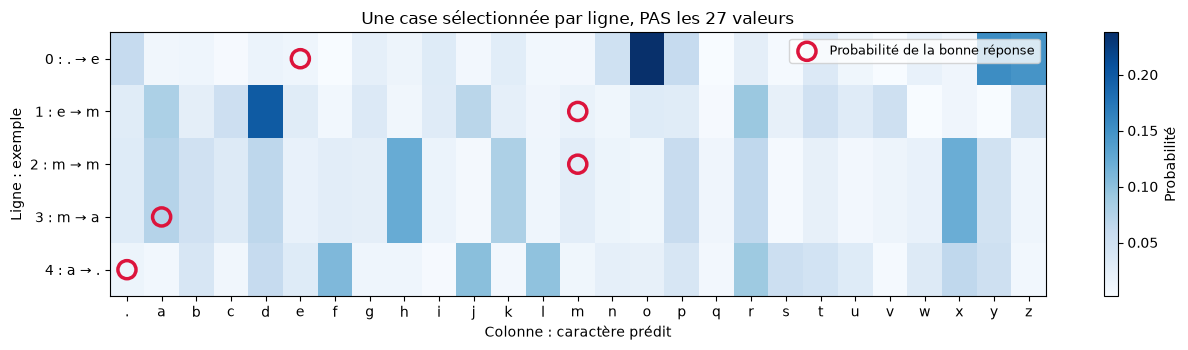

In [48]:
# Lire graphiquement les cases choisies dans (5 lignes × 27 colonnes).
# Les cercles rouges indiquent les probabilités des bonnes réponses.
fig, ax = plt.subplots(figsize=(13, 3.6))
im = ax.imshow(probs_small.detach(), aspect='auto', cmap='Blues')
ax.scatter(colonnes_cibles.numpy(), numeros_de_lignes.numpy(),
           s=170, facecolors='none', edgecolors='crimson', linewidths=2.5,
           label='Probabilité de la bonne réponse')
ax.set_xticks(range(27), [itos[j] for j in range(27)])
ax.set_yticks(range(n), [f'{i} : {a} → {b}' for i, (a, b) in enumerate(transitions)])
ax.set_xlabel('Colonne : caractère prédit')
ax.set_ylabel('Ligne : exemple')
ax.set_title('Une case sélectionnée par ligne, PAS les 27 valeurs')
ax.legend(loc='upper right', fontsize=9)
fig.colorbar(im, ax=ax, label='Probabilité')
plt.tight_layout()
plt.show()

### 6.2 — De cinq probabilités à une loss, puis à ses gradients

Nous avons maintenant les 5 probabilités des réponses correctes. La fonction de perte construite en section 3 est :

$$
\mathcal L(W)=-\frac{1}{n}\sum_{i=0}^{n-1}
\log\big(\mathrm{probs}(W)[i, y_i]\big).
$$

- `probs(W)` rappelle que **les probabilités dépendent des poids `W`**.
- `probs[i, y_i]` prend la probabilité donnée à la vraie réponse du **i-ème** exemple.
- `-log(...)` pénalise les réponses auxquelles le modèle donne une faible probabilité.
- `.mean()` fait la moyenne de ces `n` pénalités : au final, la loss est **un nombre unique**.

**Pourquoi cette loss ne suffit-elle pas ?** Deux matrices `W` différentes peuvent produire des losses différentes. Nous voulons savoir **comment la loss varie lorsque nous changeons un poids précis** : c'est exactement la question à laquelle répond une dérivée partielle.

$$
\frac{\partial \mathcal L}{\partial W_{a,b}}
$$

Elle indique la **pente locale** de la loss dans la direction du poids `W[a,b]` :

- dérivée **positive** : augmenter légèrement ce poids tend à **augmenter** la loss ;
- dérivée **négative** : augmenter légèrement ce poids tend à **diminuer** la loss ;
- dérivée proche de **zéro** : la loss change très peu pour une petite variation de ce poids.

Les **729 dérivées partielles** (27 × 27) forment ensemble le gradient de `W`. À ne pas confondre : `W` contient les poids, `W.grad` contient les **dérivées de la loss par rapport à ces poids**.

In [ ]:
# Nous reprenons EXACTEMENT le forward pass de la section 5.
# Les fonctions n'inventent pas une nouvelle architecture : elles évitent de recopier
# quatre lignes à chaque évaluation.
def forward_from_indices(x_indices, weights):
    encoded = F.one_hot(x_indices, num_classes=27).float()  # (n, 27)
    logits = encoded @ weights                              # (n, 27)
    positive_weights = logits.exp()                         # (n, 27)
    return positive_weights / positive_weights.sum(dim=1, keepdim=True)


def nll_from_probs(probs, targets):
    n = len(targets)                           # nombre de BIGRAMMES à évaluer
    indices_lignes = torch.arange(n)           # 0, 1, ..., n-1
    bonnes_probas = probs[indices_lignes, targets]  # (n,) : UNE proba par exemple
    return -bonnes_probas.log().mean()          # scalaire, la NLL moyenne


# Sans autograd : la loss est calculable, mais aucune dérivée n'est demandée.
loss_from_previous_section = nll_from_probs(probs_small, ys_small)
print('Loss sur emma :', loss_from_previous_section.item())
print('Shape des probabilités :', tuple(probs_small.shape))
print('Shape du scalaire loss :', tuple(loss_from_previous_section.shape))  # ()

Loss sur emma : 3.7693049907684326
Shape des probabilités : (5, 27)
Shape du scalaire loss : ()


### `requires_grad`, `backward()` et `W.grad` : qui fait quoi ?

Pour calculer les dérivées de la loss, **PyTorch doit observer toutes les opérations qui la relient à `W`** :

$$
W\quad\rightarrow\quad x_{\mathrm{enc}}@W
\quad\rightarrow\quad \exp
\quad\rightarrow\quad \text{normalisation}
\quad\rightarrow\quad -\log(p_{\mathrm{vraie\ réponse}})
\quad\rightarrow\quad \mathcal L.
$$

- `W.requires_grad_(True)` : indique que **nous voulons les dérivées par rapport à `W`**. Les opérations différentiables du forward construisent alors un *graphe de calcul*.
- `loss.backward()` : part de la loss (un scalaire) et **remonte la chaîne des opérations** en utilisant la règle de dérivation en chaîne (*backpropagation*).
- `W.grad` : reçoit le **gradient calculé**, c'est-à-dire un tenseur de shape **`(27, 27)`**. Ce ne sont ni des probabilités ni les « nouvelles valeurs de W ».
- `W.grad = None` : **efface le gradient de l'itération précédente**. Sinon, PyTorch additionnerait les gradients des différents appels à `backward()`.

**Crucial : `loss.backward()` ne modifie pas les poids.** Il calcule seulement les pentes dont nous avons besoin pour décider d'une mise à jour. La modification effective de `W` vient *après*.

In [50]:
# 1. Partir des mêmes poids aléatoires que dans la section 5, sans les modifier.
# .detach() coupe le lien éventuel avec un calcul précédent ; .clone() fait une copie.
W_one_step = W_demo.clone().detach().requires_grad_(True)

# 2. FORWARD : nos poids produisent des probabilités et une loss.
probs_before = forward_from_indices(xs_small, W_one_step)
loss_before = nll_from_probs(probs_before, ys_small)

# 3. BACKWARD : demander les dérivées de la loss par rapport à W.
W_one_step.grad = None
print('Gradient AVANT backward :', W_one_step.grad)
loss_before.backward()
print('Gradient APRÈS backward : shape', tuple(W_one_step.grad.shape))
print('La loss est encore la même :', round(loss_before.item(), 4))

row, col = stoi['.'], stoi['e']
old_weight = W_one_step[row, col].item()
partial_derivative = W_one_step.grad[row, col].item()
print(f"W['.', 'e'] = {old_weight:+.6f} (poids)")
print(f"∂loss/∂W['.', 'e'] = {partial_derivative:+.6f} (pente)")
print('Le poids est-il resté inchangé après backward ?',
      W_one_step[row, col].item() == old_weight)

Gradient AVANT backward : None
Gradient APRÈS backward : shape (27, 27)
La loss est encore la même : 3.7693
W['.', 'e'] = -0.029643 (poids)
∂loss/∂W['.', 'e'] = -0.197543 (pente)
Le poids est-il resté inchangé après backward ? True


### Vérification : `backward()` calcule bien une dérivée

Vous connaissez déjà les dérivées : nous pouvons vérifier une valeur de `W.grad` avec une **différence finie**. Si nous augmentons légèrement un poids de $\varepsilon$ ou le diminuons de $\varepsilon$, la pente peut s'approximer par :

$$
\frac{\partial\mathcal L}{\partial W_{a,b}}
\approx\frac{\mathcal L(W_{a,b}+\varepsilon)-\mathcal L(W_{a,b}-\varepsilon)}{2\varepsilon}.
$$

Cette approximation demande plusieurs évaluations du forward pour un seul poids : elle est utile pour **comprendre et vérifier**, pas pour entraîner les 729 poids. Le backward calcule efficacement **toutes** les dérivées par la règle de la chaîne.

In [51]:
# Test numérique sur UN poids : W['.', 'e'].
epsilon = 1e-3
with torch.no_grad():
    W_plus = W_one_step.detach().clone()
    W_minus = W_one_step.detach().clone()
    W_plus[row, col] += epsilon
    W_minus[row, col] -= epsilon
    loss_plus = nll_from_probs(forward_from_indices(xs_small, W_plus), ys_small)
    loss_minus = nll_from_probs(forward_from_indices(xs_small, W_minus), ys_small)

pente_approchee = ((loss_plus - loss_minus) / (2 * epsilon)).item()
pente_autograd = W_one_step.grad[row, col].item()
print('Pente estimée (différence finie) :', round(pente_approchee, 6))
print('Pente calculée par backward      :', round(pente_autograd, 6))
print('Même ordre de grandeur ?', abs(pente_approchee - pente_autograd) < 1e-3)
assert abs(pente_approchee - pente_autograd) < 1e-3

Pente estimée (différence finie) : -0.197649
Pente calculée par backward      : -0.197543
Même ordre de grandeur ? True


### 6.3 — La mise à jour : pourquoi soustraire `learning_rate * grad` ?

Nous avons une **direction locale** à suivre. Pour faire **baisser** la loss, nous avançons dans la direction **opposée au gradient** :

$$
\boxed{W_{\mathrm{nouveau}}=W_{\mathrm{ancien}}-\eta\,\nabla_W\mathcal L}
$$

Ici $\eta$ (`learning_rate`) détermine **la taille du pas**, pas sa direction :

- **Petit** learning rate : changements prudents mais parfois très lents ;
- **Plus grand** : peut progresser plus vite ;
- **Trop grand** : peut dépasser une bonne région, osciller ou diverger.

Exemple d'un seul poids : si `W[a,b] = 0.40` et `W.grad[a,b] = +0.20`, avec `learning_rate = 0.1` :

$$
W_{a,b}^{\mathrm{nouveau}}=0.40-0.1\times 0.20=0.38.
$$

Le gradient positif nous fait **diminuer** le poids. Si le gradient avait été négatif, la soustraction l'aurait **augmenté**. Une mise à jour change **tous les poids** de `W`, chacun selon son propre gradient.

**Important :** la direction `-grad` améliore la loss **localement** pour un pas suffisamment petit ; ce n'est pas une garantie qu'un très grand learning rate améliore la loss après chaque étape.

In [53]:
# Montrer la taille du pas AVANT de modifier les poids.
# Nous repartons du même W et des mêmes gradients pour comparer équitablement.
print(f"Loss de départ : {loss_before.item():.5f}")
for lr in [0.0, 0.1, 1.0, 10.0]:
    with torch.no_grad():
        W_candidat = W_one_step - lr * W_one_step.grad
        loss_candidat = nll_from_probs(
            forward_from_indices(xs_small, W_candidat), ys_small
        ).item()
    print(f"learning_rate={lr:>4} : loss après UN pas = {loss_candidat:.5f}")

# Faire réellement UN pas avec un learning rate raisonnable sur ces 5 exemples.
learning_rate_demo = 0.1
with torch.no_grad():
    # Ne pas enregistrer dans le graphe une opération dont l'objectif est
    # de MODIFIER des paramètres, pas de calculer la loss.
    W_one_step -= learning_rate_demo * W_one_step.grad

loss_after = nll_from_probs(forward_from_indices(xs_small, W_one_step), ys_small)
print(f"\nLoss avant : {loss_before.item():.5f} ; après : {loss_after.item():.5f}")
print(f"W['.', 'e'] avant : {old_weight:+.6f}")
print(f"Gradient calculé : {partial_derivative:+.6f}")
print(f"W['.', 'e'] après : {W_one_step[row, col].item():+.6f}")
assert loss_after.item() < loss_before.item(), 'Pour cet exemple et ce pas, la loss devrait baisser.'

Loss de départ : 3.76930
learning_rate= 0.0 : loss après UN pas = 3.76930
learning_rate= 0.1 : loss après UN pas = 3.74921
learning_rate= 1.0 : loss après UN pas = 3.56937
learning_rate=10.0 : loss après UN pas = 1.93173

Loss avant : 3.76930 ; après : 3.74921
W['.', 'e'] avant : -0.029643
Gradient calculé : -0.197543
W['.', 'e'] après : -0.009889


### 6.4 — Répéter l'opération sur **tous** les bigrammes

Avec `emma`, nous avons utilisé `n = 5`, juste pour **voir les cases et les calculs**. Nous voulons maintenant apprendre à partir des milliers de prénoms :

- `xs` contient l'indice du caractère courant pour chaque bigramme du dataset ;
- `ys` contient l'indice du vrai caractère suivant ;
- `M = len(ys)` est le **nombre total de transitions**, pas le nombre de caractères possibles (27) ;
- `torch.arange(M)` donne les **M numéros de lignes**, et `ys` les **M colonnes cibles**.

Donc **une seule ligne de code** calcule la bonne probabilité pour *chaque observation* :

```python
probas_correctes = probs[torch.arange(M), ys]  # (M,)
loss = -probas_correctes.log().mean()            # scalaire
```

La descente de gradient sur **tout le corpus** répète les cinq opérations suivantes :

1. **Forward** : produire `probs` à partir de `W` ;
2. **Loss** : sélectionner les bonnes probabilités, calculer la NLL moyenne ;
3. **Remise à zéro** : `W.grad = None` ;
4. **Backward** : `loss.backward()` calcule les pentes ;
5. **Mise à jour** : `W -= learning_rate * W.grad` sous `torch.no_grad()`.

C'est **la même loss que pour le comptage** et le **même forward pass** que celui construit en section 5. La seule nouveauté est de **répéter** le calcul des gradients et l'ajustement des poids.

In [54]:
# Construire tous les exemples (x = caractère courant, y = caractère suivant).
xs_list, ys_list = [], []
for w in words:
    sequence = ["."] + list(w) + ["."]
    for ch1, ch2 in zip(sequence, sequence[1:]):
        xs_list.append(stoi[ch1])
        ys_list.append(stoi[ch2])

xs = torch.tensor(xs_list, dtype=torch.long)
ys = torch.tensor(ys_list, dtype=torch.long)
M = len(ys)
xenc = F.one_hot(xs, num_classes=27).float()

print('Nombre de prénoms :', len(words))
print('Nombre de transitions (M) :', M)
print('xs.shape :', tuple(xs.shape), '| ys.shape :', tuple(ys.shape))
print('xenc.shape :', tuple(xenc.shape))
rows_full = torch.arange(M)
print('torch.arange(M) :', rows_full[:5].tolist(), '... jusqu’à', rows_full[-1].item())
print('Les 5 premières paires (numéro de ligne, vraie colonne) :',
      list(zip(torch.arange(5).tolist(), ys[:5].tolist())))

Nombre de prénoms : 32033
Nombre de transitions (M) : 228146
xs.shape : (228146,) | ys.shape : (228146,)
xenc.shape : (228146, 27)
torch.arange(M) : [0, 1, 2, 3, 4] ... jusqu’à 228145
Les 5 premières paires (numéro de ligne, vraie colonne) : [(0, 5), (1, 13), (2, 13), (3, 1), (4, 0)]


### Mini-expérience — Changer le learning rate, garder tout le reste identique

Pour comparer honnêtement `0.1`, `1` et `50`, nous repartons **des mêmes 729 poids initiaux** et utilisons **les mêmes données** à chaque essai. Seul le learning rate change.

Avant de lancer le code, demandez-vous : **les trois modèles suivront-ils la même trajectoire ?** Le graphique révélera les différences de vitesse de diminution de la loss.

> **Nuance importante :** `50` est adapté ici à ce **petit modèle bigramme**, à une loss **moyennée** sur toutes les transitions et à l'échelle de ses gradients. Dans un grand Transformer, `50` serait généralement catastrophique. Le learning rate ne se choisit jamais indépendamment du modèle et de l'optimisation.

In [55]:
# Tous les essais commencent au même W, pour isoler l'effet du learning rate.
initial_W = torch.randn((27, 27), generator=torch.Generator().manual_seed(SEED))


def train_bigram(learning_rate, steps=100):
    W = initial_W.clone().detach().requires_grad_(True)
    history = []

    for step in range(steps):
        # (1) FORWARD : W -> logits -> probabilités
        logits = xenc @ W                                 # (M, 27)
        counts = logits.exp()                             # poids positifs
        probs = counts / counts.sum(dim=1, keepdim=True)  # (M, 27)

        # (2) LOSS : une bonne colonne par ligne, puis la NLL moyenne
        rows = torch.arange(M)                            # (M,) = numéros d'exemples
        correct_probs = probs[rows, ys]                    # (M,) = une proba par exemple
        loss = -correct_probs.log().mean()                 # scalaire
        history.append(loss.item())

        # (3) REMISE À ZÉRO : ne pas cumuler avec le gradient précédent
        W.grad = None

        # (4) BACKWARD : remplit W.grad, mais ne change PAS W
        loss.backward()                                   # W.grad : (27, 27)

        # (5) UPDATE : maintenant seulement, changer les poids
        with torch.no_grad():
            W -= learning_rate * W.grad

    return W.detach(), history


experiments = {}
for rate in [0.1, 1.0, 50.0]:
    weights, history = train_bigram(rate, steps=100)
    experiments[rate] = (weights, history)
    print(f"learning_rate={rate:>4} : loss {history[0]:.4f} -> {history[-1]:.4f}")

learning_rate= 0.1 : loss 3.7590 -> 3.6733
learning_rate= 1.0 : loss 3.7590 -> 3.1887
learning_rate=50.0 : loss 3.7590 -> 2.4729


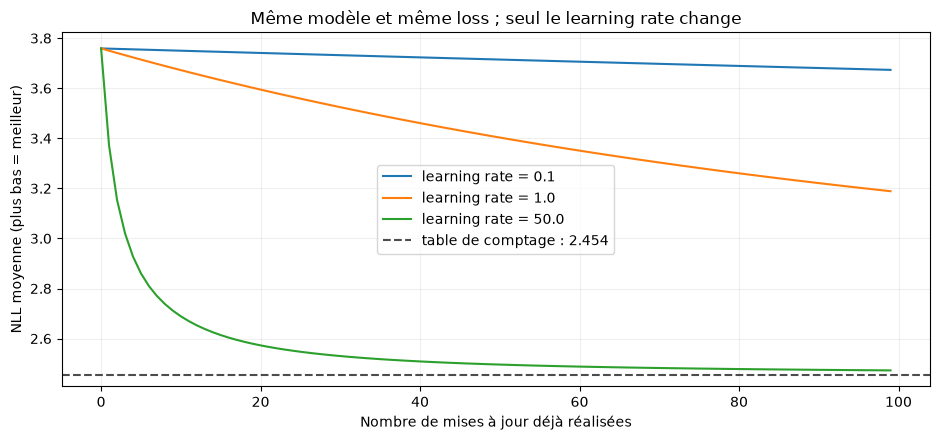

In [56]:
# Regarder la NLL au fil des itérations.
# La ligne horizontale est la NLL du modèle obtenu directement par comptage.
fig, ax = plt.subplots(figsize=(9.5, 4.5))
for rate, (_, history) in experiments.items():
    ax.plot(range(len(history)), history, label=f'learning rate = {rate}')
ax.axhline(loss_comptage, color='black', linestyle='--', alpha=0.7,
           label=f'table de comptage : {loss_comptage:.3f}')
ax.set_xlabel('Nombre de mises à jour déjà réalisées')
ax.set_ylabel('NLL moyenne (plus bas = meilleur)')
ax.set_title('Même modèle et même loss ; seul le learning rate change')
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

### 6.5 — Lire les courbes et préparer la comparaison finale

**Ce que le graphique démontre :** les trois essais optimisent **la même loss** à partir de **la même initialisation**. Un taux faible progresse lentement ; un taux mieux adapté fait baisser le score plus vite. Un taux trop élevé *pourrait* aussi provoquer une divergence : nous avons vu avec une seule mise à jour pourquoi ce risque existe.

**Ce que le graphique ne démontre pas :** que les **27 probabilités de chaque ligne** correspondent déjà à celles du comptage. Deux modèles peuvent avoir une loss proche sans que toutes leurs sorties soient parfaitement identiques.

**Questions de vérification :**

1. `torch.arange(M)` donne-t-il les **colonnes des caractères possibles**, ou les **numéros des observations** ? → Les numéros des observations.
2. À quoi sert `ys` dans `probs[torch.arange(M), ys]` ? → À choisir **la vraie réponse dans chaque ligne**.
3. `loss.backward()` fait-il évoluer les poids ? → Non, il calcule leurs gradients.
4. Si `W.grad[a,b]` est positif, dans quel sens bouge `W[a,b]` lors d'une descente de gradient ? → Il **diminue**, à cause du signe moins.
5. Pourquoi `W.grad = None` avant chaque `backward()` ? → Pour ne pas ajouter les nouvelles pentes aux précédentes.

**Transition vers la section 7 :** « Le réseau a appris à réduire la même loss que notre modèle de comptage. Maintenant, vérifions une chose plus concrète : **après la lettre `a`, prédit-il presque les mêmes probabilités que notre table `P` ?** »

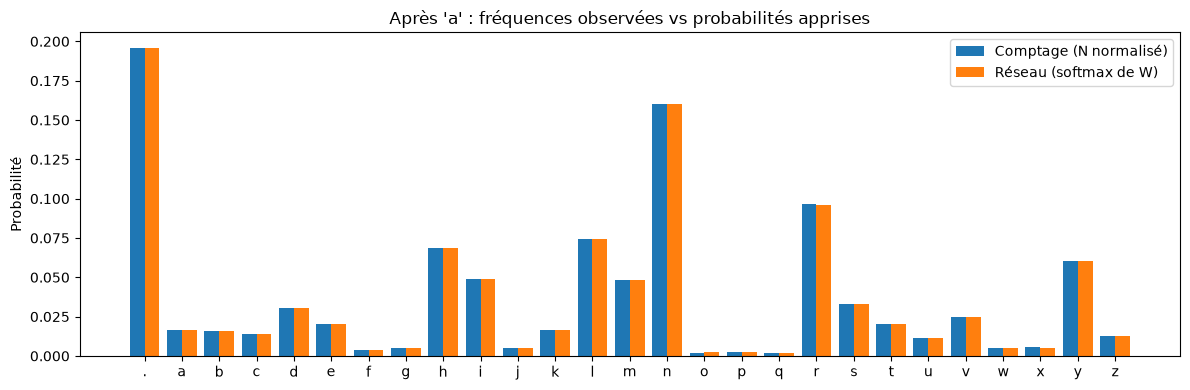

Comptage : 2.4540 ; réseau : 2.4727
Écart moyen absolu entre tables : 0.006576161365956068


In [57]:
W_trained = experiments[50.0][0]
with torch.no_grad():
    learned_probs = W_trained.exp()
    learned_probs /= learned_probs.sum(dim=1, keepdim=True)

current_char = 'a'
i = stoi[current_char]
fig, ax = plt.subplots(figsize=(12, 4))
x = torch.arange(27).numpy()
ax.bar(x - .2, P[i].numpy(), width=.4, label="Comptage (N normalisé)")
ax.bar(x + .2, learned_probs[i].numpy(), width=.4, label="Réseau (softmax de W)")
ax.set_xticks(x, [itos[j] for j in range(27)])
ax.set_title(f"Après '{current_char}' : fréquences observées vs probabilités apprises")
ax.set_ylabel("Probabilité")
ax.legend(); plt.tight_layout(); plt.show()

# NLL du réseau sur le dataset, calculée sans construire un nouveau one-hot.
network_loss = -learned_probs[xs, ys].log().mean().item()
print(f"Comptage : {loss_comptage:.4f} ; réseau : {network_loss:.4f}")
print("Écart moyen absolu entre tables :", (P - learned_probs).abs().mean().item())

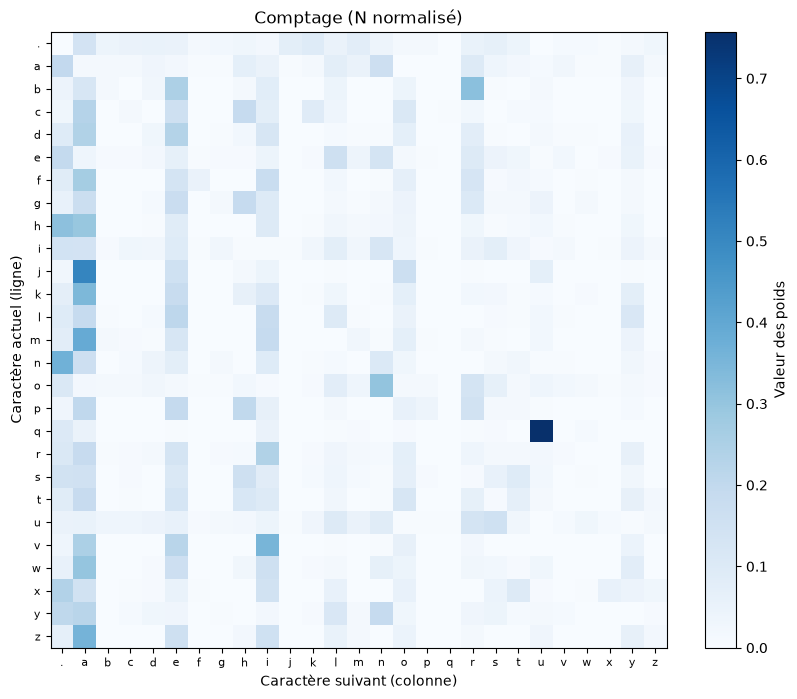

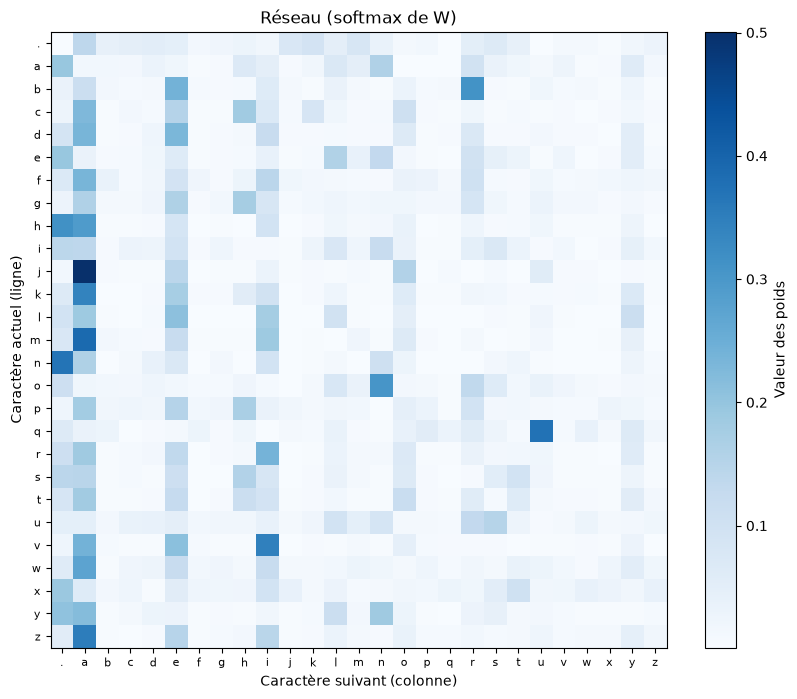

In [80]:
plot_matrice_caracteres(
    P,
    itos,
    title="Comptage (N normalisé)",
    cbar_label="Valeur des poids",
)
plt.show()
plot_matrice_caracteres(
    learned_probs,
    itos,
    title="Réseau (softmax de W)",
    cbar_label="Valeur des poids",
)
plt.show()

### Que prouve réellement la comparaison finale ?

Une loss proche de `2,45` ne garantit pas à elle seule que **toutes** les distributions soient identiques. Le graphique compare donc, pour un caractère fixé (`a`), **les 27 probabilités** après ce caractère :

- barres **comptage** : `P[stoi['a']]`, issues des proportions dans `names.txt` ;
- barres **réseau** : `softmax(W_trained[stoi['a']])`, issues des poids ajustés par descente de gradient.

Lorsque les barres se ressemblent, on voit concrètement que le réseau est en train d'**apprendre les fréquences des bigrammes**. Ce n'est pas une mémoire magique des prénoms : le modèle conserve uniquement le dernier caractère.

**Nuance :** si une transition n'apparaît jamais dans le corpus, la table sans smoothing lui attribue `0`, alors que le softmax d'une matrice finie donne toujours une probabilité strictement positive. On parle donc de **distributions proches**, pas toujours exactement égales.

### Générer avec le réseau entraîné

Aucune nouvelle logique d'échantillonnage n'est nécessaire : `learned_probs` est une table de probabilités, tout comme `P`. On peut donc réutiliser **exactement la même fonction**.

In [81]:
print("Modèle de comptage :")
for name in sample_names_from_table(P, n=10, seed=42):
    print(f"- {name}")
print("Réseau entraîné   :")
for name in sample_names_from_table(learned_probs, n=10, seed=42):
    print(f"- {name}")

Modèle de comptage :
- anugeenvi
- s
- mabian
- dan
- stan
- silaylelaremah
- li
- le
- epiachalen
- diza
Réseau entraîné   :
- anugeenvi
- s
- mabian
- dxfme
- nn
- silaylelaremah
- li
- le
- epjachalen
- diza


### Synthèse — à pouvoir expliquer sans regarder le code

**Modèle par comptage :**

$$
P_{ij}=\frac{N_{ij}}{\sum_k N_{ik}}.
$$

**Modèle neuronal :**

$$
P_{ij}(W)=\frac{e^{W_{ij}}}{\sum_k e^{W_{ik}}}.
$$

Le premier **calcule directement** les fréquences conditionnelles. Le second **apprend** des paramètres en minimisant la même negative log-likelihood. Comme chaque ligne de `W` est libre, ses probabilités peuvent approcher celles du comptage. Les transitions jamais observées gardent une probabilité strictement positive avec des poids finis : l'égalité exacte n'est donc pas toujours atteignable.

**Les quatre invariants pour la suite du cursus :**

1. Le modèle émet des **logits**.
2. Le **softmax** les transforme en probabilités.
3. La **negative log-likelihood moyenne** mesure les erreurs de prédiction.
4. La **descente de gradient** ajuste les poids pour diminuer cette perte.

**Question finale :** si un bigramme se contente de mémoriser le caractère précédent, comment utiliser un contexte de deux, trois ou davantage de caractères **sans compter toutes les combinaisons possibles** ? C'est la raison d'être des architectures suivantes.

---
## Annexe — Vérification individuelle (facultative, après le cours)

**Sans exécuter de code, répondre :**

1. Pourquoi `P[stoi['a']]` contient-il 27 valeurs qui somment à 1 ?
2. Quelle est la dimension de `xenc @ W` si le batch contient 200 bigrammes ?
3. Pourquoi la NLL augmente-t-elle fortement quand le modèle donne une très faible probabilité au vrai prochain caractère ?
4. Pourquoi la direction de mise à jour est-elle `-W.grad` ?
5. Quelle limite du bigramme les modèles des chapitres suivants devront-ils dépasser ?

**Petit défi de code :** changer `current_char = 'a'` dans le graphique comparatif final pour `e`, `m` ou `.`. Quelles lignes sont les plus faciles à apprendre ?

*Référence : Andrej Karpathy, [makemore](https://github.com/karpathy/makemore). Notebook pédagogique adapté et réorganisé pour un cours de deux heures.*